# AI-Assisted Co-Design of a Transformer-Feedback Regulated-Cascode TIA in IHP SG13G2: openEMS-Trained Surrogates for Planar Transformers

**Submission to the Code-a-Chip Competition 2027 (ISSCC)**

SPDX-License-Identifier: Apache-2.0

| Team member | Affiliation | Contact |
|:--|:--|:--|
| *Name 1* | *Affiliation* | *e-mail* |
| *Name 2* | *Affiliation* | *e-mail* |

## Introduction

The transimpedance amplifier (TIA) in front of a photodiode sets the sensitivity and the speed of an optical receiver.
The photodiode and the pad add a capacitance of 220 fF at the input node, and the bandwidth of a plain common-base input stage is
bounded by this capacitance and by the transconductance of the input transistor, $BW \approx g_m / (2\pi C_{pd})$.
Raising $g_m$ means more current, more noise-power and more device capacitance.

A transformer in the emitter-base loop of the input transistor increases the effective transconductance without extra
current. The primary winding (Lp) is placed in the emitter path, the secondary winding (Ls) feeds the base. If the
secondary voltage is in phase opposition to the emitter voltage, the transistor sees

$$ g_m' = (1 + n\,k)\, g_m, \qquad n = \sqrt{L_s / L_p}, $$

so the input resistance of the regulated cascode falls to $1/g_m'$ and the bandwidth increases. The gain depends on the coupling factor $k$ and on the turn ratio $n$, but a physical
transformer also brings series resistance, a self-resonance frequency (SRF) and layout parasitics. Whether a
planar transformer in the available metal stack can reach a coupling that pays off is therefore an electromagnetic question, which a
schematic simulation with ideal coupled inductors cannot answer.

This notebook answers it with a complete open-source flow in the IHP SG13G2 BiCMOS process:

* a parametric generator draws square planar transformers (interleaved or stacked broadside) in TopMetal1/TopMetal2,
* openEMS simulates them on a Ray cluster and produces a 4-port S-parameter data set,
* residual neural networks learn the S-parameters as a function of the layout parameters,
* ngspice evaluates the complete TIA with the transformer as an S-parameter block, and CMA-ES optimises the circuit and the transformer geometry,
* the final layouts are simulated again with openEMS and compared with the surrogate.

The design target is a differential transimpedance of at least 59 dB$\Omega$ at 1 GHz into 2 x 50 $\Omega$, a bandwidth of at least 26 GHz (and as much more as possible), an input noise of at most
21.3 pA/$\sqrt{\mathrm{Hz}}$ and a power of at most 28.2 mW from 2.5 V, with gain peaking below 1 dB and a group-delay variation below 10 ps.

## Notebook Overview

1. **TIA topology and specification**: the three amplifier stages and the target table.
2. **Transformer layout generator**: the 9 parameters and the GDS generator.
3. **Massive EM data generation**: openEMS on a Ray cluster, a fast and validated simulation setting, and two batches of layouts.
4. **What do the EM data say?**: inductances, coupling factors and self-resonance frequencies of the simulated layouts.
5. **Neural surrogates**: residual MLP ensembles for the transformer (4-port) and the spirals (2-port).
6. **SPICE co-simulation**: S-parameter blocks in ngspice and the bias window of the SG13G2 npn.
7. **Co-design with CMA-ES**: cost function and optimisation modes.
8. **Transformer versus no transformer**: ideal and real (EM) transformers in the complete TIA.
9. **EM verification** of the optimised design.
10. **Conclusion and to do.**

### Special Hint

All scripts are written to files by the `%%writefile` cells, so the notebook is self-contained. The cells that need a Ray cluster
(`emx_sim.py`) or hours of CPU time (optimisation, surrogate training) are shown as the command that was executed; the analysis cells read the
files that these runs wrote to `results/`, `models/` and `SPData/`.

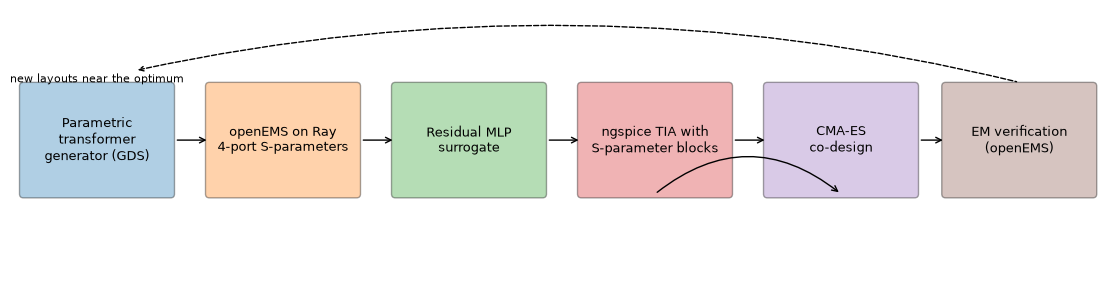

In [1]:
# Workflow of the notebook
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(14, 3.4)); ax.axis('off'); ax.set_xlim(0, 14); ax.set_ylim(0, 3.4)
boxes = [('Parametric\ntransformer\ngenerator (GDS)', 0.1, 'C0'), ('openEMS on Ray\n4-port S-parameters', 2.5, 'C1'),
         ('Residual MLP\nsurrogate', 4.9, 'C2'), ('ngspice TIA with\nS-parameter blocks', 7.3, 'C3'),
         ('CMA-ES\nco-design', 9.7, 'C4'), ('EM verification\n(openEMS)', 12.0, 'C5')]
for t, x, c in boxes:
    ax.add_patch(FancyBboxPatch((x, 1.0), 1.9, 1.4, boxstyle='round,pad=0.05', fc=c, ec='k', alpha=0.35))
    ax.text(x + 0.95, 1.7, t, ha='center', va='center', fontsize=9)
for i in range(len(boxes) - 1):
    ax.annotate('', xy=(boxes[i + 1][1], 1.7), xytext=(boxes[i][1] + 1.95, 1.7), arrowprops=dict(arrowstyle='->'))
ax.annotate('', xy=(7.3 + .95, 1.0), xytext=(9.7 + .95, 1.0), arrowprops=dict(arrowstyle='<-', connectionstyle='arc3,rad=0.4'))
ax.annotate('new layouts near the optimum', xy=(12.95, 2.45), xytext=(1.05, 2.45), ha='center', fontsize=8,
            arrowprops=dict(arrowstyle='<-', connectionstyle='arc3,rad=-0.12', ls='--'))
plt.show()

## Requirements

* Linux, Python 3.12, a C++ toolchain (openEMS and ngspice are built from source into `../opt`)
* **openEMS 0.0.37** with CSXCAD (Python bindings), **ngspice 47** with XSPICE, the open IHP-SG13G2 PDK
* Python packages: `numpy`, `scipy`, `matplotlib`, `scikit-rf`, `gdspy`, `cairosvg`, `torch`, `optuna`, `cmaes`, `ray`, `nbformat`
* A Ray cluster for the EM simulations (a single machine works but the 1000+ layouts take several days on one node;
  the notebook used 4 CPUs per simulation on a cluster of about 100 cores). A GPU is not required.

The installation script `install_env.sh` in the parent directory builds the tool chain; the cells below prepare the working
directory.

## Environment Setup

The PDK is cloned once, the EM helper modules and the stack description `SG13G2.xml` are copied from the PDK, and the
folders for the layouts and the EM results are created.

In [2]:
%%bash
cd ..
# PDK (skip if present)
[ -d IHP-Open-PDK ] || git clone --depth 1 https://github.com/IHP-GmbH/IHP-Open-PDK.git
cd TIA_Diff_work_new
ln -sfn ../IHP-Open-PDK IHP-Open-PDK
mkdir -p EMLOG GDS INFO PNG SPData SVG_TEMP results models
ls

bias_sweep.py
check_dataset.py
check_k.py
check_round.py
chk_batch2.py
chk_compare.py
chk_lbw2.py
ch

k_lbw.py
chk_leads.py
chk_main_progress.py
chk_model_cal.py
chk_model.py
chk_ns2.py
chk_ratio.py
chk

_usable.py
chk_valid.py
chk_xfmr_all.py
codesign.py
compare_fast.py
decide_em_settings.py
dump_ref_m

d.py
EMLOG
em_stats.py
emx_sim.py
Failed_List.txt
GDS
gen_check_stack.py
IHP-Open-PDK
INFO
launch_af

ter_select.sh
layout_bw.py
make_notebook.py
models
modules
old_topology
PNG
__pycache__
results
run_

...

un_main_batch.sh
run_ngspice.sh
run_ns1region.sh
run_pipeline.sh
run_select.sh
run_validation.sh
sca

n_broadside.py
scan_model2.py
scan_model3.py
scan_model.py
scan_new.py
scan_ratio.py
scan_stack.py
s

can_swap.py
scan_wide.py
SG13G2.xml
simulator_openems.py
SPData
spiral_gen.py
status2.sh
status3.sh


status.sh
surrogate.py
SVG_TEMP
TIA_Diff_new_CoDesign.ipynb
tia_sim.py
verify.py
wait_emx.sh
wait_id

eal.sh
xfmr_gen.py
xfmr_model.py
xfmr_select_batch2.py
xfmr_select_old_wheeler.py
xfmr_select.py


In [3]:
%%bash
# openEMS front-end modules of the PDK and the metal-stack description
PDK=../IHP-Open-PDK/ihp-sg13g2/libs.tech/openems/openems_ihp_sg13g2/workflow
[ -d modules ] || cp -r $PDK/modules .
[ -f SG13G2.xml ] || cp $PDK/SG13G2.xml .
# batch runs: disable the preview of the simulation setup (the number of FDTD threads is read from OPENEMS_THREADS by the same file)
sed -i 's/^\(\s*\)if 1 in excite_portnumbers:/\1if False and 1 in excite_portnumbers:/' modules/util_simulation_setup.py
grep -n "if False and 1 in excite_portnumbers\|OPENEMS_THREADS" modules/util_simulation_setup.py

294:        if False and 1 in excite_portnumbers:  # only for first port excitation
315:            

    n_threads = int(os.environ.get('OPENEMS_THREADS', 0))


In [4]:
%%bash
# Python environment (the tool chain of install_env.sh provides openEMS, CSXCAD and ngspice)
../.venv/bin/pip install numpy scipy matplotlib scikit-rf gdspy cairosvg torch optuna cmaes ray nbformat
cat run_ngspice.sh

.12/site-packages (1.26.4)


.12/site-packages (1.17.1)


thon3.12/site-packages (3.11.2)


hon3.12/site-packages (2.1.0)


.12/site-packages (1.6.13)


...

python3.12/site-packages (from requests->ray) (3.20)


lib/python3.12/site-packages (from requests->ray) (2.8.0)


/lib/python3.12/site-packages (from requests->ray) (2026.7.22)


export PDK_ROOT=/content/Code_a_Chip_2027/TIA_Diff_work_new/IHP-Open-PDK
export PDK

=ihp-sg13g2
/content/Code_a_Chip_2027/TIA_Diff_work_new/../opt/bin/ngspice -b "$@"


The Ray head node is started once with `start_ray_cluster.sh`; every worker machine connects to it. Authentication is by token:

```bash
export RAY_AUTH_MODE=token
export RAY_ADDRESS=<head-node>:6379
```

`run_ngspice.sh` (printed above) is the thin wrapper that sets `PDK_ROOT`/`PDK` and runs ngspice in batch mode.

## 1. TIA Topology and Specification

The amplifier has three stages (the netlist is generated in Section 6):

* **Stage 1, transformer RGC input.** The photodiode current $I_{in}$ with the 220 fF input capacitance $C_{pd}$ enters through a spiral inductor L1 into the emitter of Q1. The primary of the transformer (ports P and $\bar P$) sits between the emitter and the resistor R2 that sets the bias current. The secondary (ports S and $\bar S$) connects the base of Q1 to the bias voltage Vb. The winding sense is chosen so that $S \to \bar S$ circulates opposite to $P \to \bar P$, which gives a positive coupling between P and $\bar S$ and $g_m' = (1 + n k) g_m$. R1 is the collector load of Q1.
* **Stage 2, transimpedance gain stage.** A common-emitter transistor Q2 with shunt feedback Rf from its collector to its base, the load R4 and an emitter network R3 $\|$ C1 (MIM capacitor).
* **Stage 3, output buffer.** A single-ended to differential pair Q3/Q4 with tail current source. The base of Q4 follows a low-pass replica of the Q3 base so that no offset is created. The 50 $\Omega$ loads include a shunt-peaking spiral inductor Lb at each output.

Stage 1 plus stage 3 alone reaches only 14 to 16 GHz with or without the transformer, therefore all results below use the full
three-stage amplifier (stages 1+2+3).

| Quantity | Target |
|:--|:--|
| Photodiode + pad capacitance Cpd | 220 fF (150 fF + 70 fF) |
| Differential transimpedance at 1 GHz (2 x 50 $\Omega$) | $\ge$ 59 dB$\Omega$ |
| -3 dB bandwidth | $\ge$ 26 GHz, then as wide as possible |
| Input-referred noise current (band average) | $\le$ 21.3 pA/$\sqrt{\mathrm{Hz}}$ |
| Power from VCC = 2.5 V | $\le$ 28.2 mW |
| Gain peaking | $\le$ 1 dB |
| Group-delay variation (1 GHz to BW) | $\le$ 10 ps |

The central question of the notebook is **how much more bandwidth the transformer gives than a plain common-base input stage with the same
amplifier stages (no transformer, "noX")**, when the transformer is a real layout in SG13G2 and not an ideal coupled-inductor model.

## 2. Transformer Layout Generator

The generator draws a square planar transformer. The secondary is an `ns`-turn spiral. The primary consists of `m` parallel rings
that are placed either **between** the secondary turns (interleaved, `sb = 0`) or **under** the outer secondary turns (stacked broadside,
`sb = 1`): the primary rings are in TopMetal1 and lie directly below the secondary turns in TopMetal2, and TopVia2 arrays join the two layers where a
cross-over is needed. The stacked version needs `pb = 1`. Stacking
couples the windings over the full conductor width, so it is the way to a high $k$, at the price of a higher inter-winding capacitance.

| Parameter | Range | Meaning |
|:--|:--|:--|
| `w` | 3 to 20 $\mu$m | width of the secondary track |
| `s` | 2 to 6 $\mu$m | spacing between tracks |
| `ns` | 1 to 3 | secondary turns |
| `m` | 1 to 2 ($\le$ min(2, `ns`)) | parallel primary rings |
| `D` | 30 to 200 $\mu$m | outer dimension |
| `pb` | 0 / 1 | exit direction of $\bar P$ (right/bottom) |
| `sb` | 0 / 1 | 0 interleaved, 1 stacked broadside |
| `u` | 10 to 70 % | position of the $\bar P$/$\bar S$ port along the edge |
| `wp` | 3 to 20 $\mu$m | width of the primary track (the track pitch is `max(w, wp) + s`) |

P and S leave to the left (P directly above S), $\bar P$ and $\bar S$ leave at the bottom (stacked) or at the right (interleaved).
Metal4 forms a ground ring, and four Metal4-to-TopMetal2 ports (layers 201 to 204) are placed for the EM simulation.
The script is listed below; `python xfmr_gen.py START END SEED` draws random valid layouts into `GDS/`, `PNG/` and `INFO/`.

In [5]:
%%writefile xfmr_gen.py
# Parametric interleaved planar transformer (shape of Fig. 12 of Li & Palermo, JSSC 2013) for SG13G2.
# Secondary S: ns full turns + a partial turn of square TopMetal2 spiral. Primary P: m half-turn TopMetal2 rings
# (m = 1 single winding, m = 2 double winding, the two rings in parallel) interleaved with the outer secondary turns
# (tracks from outside: S0, P0, S1, P1, ..., then the remaining S turns).
# P and S start on the left side (P just above S); the windings stop on the RIGHT side and Pbar / Sbar leave straight
# to the right through short TopMetal1 underpasses below the outer secondary turns. Metal4 ground ring, 4 via ports
# Metal4->TopMetal2:  1 = P (-> Q1 emitter), 2 = Pbar (-> R2), 3 = S (-> Q1 base), 4 = Sbar (-> Vb).
# Current flows S -> Sbar counter-clockwise and P -> Pbar clockwise (opposite senses).
# Geometry: [w, s, ns, m, D, pb, sb, u, wp]  (secondary track width, spacing, secondary full turns, parallel primary rings, outer side
# [um], pb = Pbar leaves right (0) / down (1), sb = 1: stacked (broadside) variant, primary rings on TM1 directly below
# the outer secondary turns on TM2 (same centre lines), Pbar and Sbar both leave downwards (needs pb = 1), u = position of
# the Pbar end in % of D, wp = primary track width (optional, default = w); the track pitch is max(w, wp) + s)
# Usage: python xfmr_gen.py start end seed [codesign_best.json [--all-focus]]
import gdspy
import cairosvg
import os
import random
import sys

TM1, TV2, TM2, M4 = 126, 133, 134, 50
PORT_LAYERS = (201, 202, 203, 204)
GND_MARGIN = 20   # coil bbox to ground ring spacing (um)
GND_WIDTH = 30
PORT_LEN = 4
D_MIN, D_MAX = 30, 200
U_MIN, U_MAX = 10, 70
W_MIN, W_MAX = 3, 20
KEYS = ('w', 's', 'ns', 'm', 'D', 'pb', 'sb', 'u', 'wp')

data_path = os.path.dirname(os.path.abspath(__file__)) + '/'
gdspy.library.use_current_library = False
lib = gdspy.GdsLibrary(name='BatchGen_Xfmr')
lib.precision = 5e-9


def via_array(cx, cy, sx, sy, size=0.9, space=1.06, enc=0.5, layer=TV2):
	nx = int((sx - 2 * enc + space) // (size + space))
	ny = int((sy - 2 * enc + space) // (size + space))
	x0 = cx - (nx * (size + space) - space) / 2
	y0 = cy - (ny * (size + space) - space) / 2
	return [gdspy.Rectangle((x0 + i * (size + space), y0 + j * (size + space)),
							(x0 + i * (size + space) + size, y0 + j * (size + space) + size), layer=layer)
			for i in range(nx) for j in range(ny)]


def via_stack(cx, cy, w):
	return [gdspy.Rectangle((cx - w / 2, cy - w / 2), (cx + w / 2, cy + w / 2), layer=l) for l in (TM1, TM2)] \
		+ via_array(cx, cy, w, w)


def offsets(w, s, ns, m, stack=0, wp=None):
	"""Pitch p, secondary turn offsets o[t] and primary ring offsets q[k] (distance of the centre line from the outer edge).
	stack = 1: the primary rings (TM1) lie directly below the outer secondary turns (TM2), same offsets."""
	p = max(w, w if wp is None else wp) + s
	if stack:
		return p, [t * p for t in range(int(ns))], [k * p for k in range(int(m))]
	kinds = []
	for t in range(int(ns)):
		kinds.append('S')
		if t < m:
			kinds.append('P')
	o = [i * p for i, c in enumerate(kinds) if c == 'S']
	q = [i * p for i, c in enumerate(kinds) if c == 'P']
	return p, o, q


def is_valid(w, s, ns, m, D, pb=0, sb=0, u=50, wp=None):
	wp = w if wp is None else wp
	p, o, q = offsets(w, s, ns, m, sb, wp)
	if not (W_MIN <= w <= W_MAX and W_MIN <= wp <= W_MAX and s >= 2 and 1 <= ns <= 3 and 1 <= m <= min(2, ns)
			and D_MIN <= D <= D_MAX and pb in (0, 1) and sb in (0, 1) and U_MIN <= u <= U_MAX):
		return False
	if sb and not pb:      # stacked variants: Pbar and Sbar both leave downwards
		return False
	fr = frame(w, s, ns, m, D, pb, sb, u, wp)
	if D - 2 * fr['oe'] < max(3 * p, 10):         # hole inside the last (partial) secondary turn
		return False
	if sb:          # Sbar bar left of the lowest Pbar bar and clear of the inner secondary turn
		return fr['x_se'] >= fr['oe'] + 2 * p and min(fr['x_pe']) >= q[-1] + 2 * p and max(fr['x_pe']) <= D - q[-1] - 2 * p
	if pb == 0:     # lowest Pbar end clear of the Sbar route (3 pitches) and below the top edge of its ring
		return fr['y_pe'][-1] >= fr['y_e'] + 3 * p and fr['y_pe'][0] <= D - q[-1] - 2 * p
	# Pbar ends on the bottom edge: right of the P start bar, left of the right edge
	return fr['x_pe'][0] >= q[-1] + 2 * p and fr['x_pe'][-1] <= D - q[-1] - 2 * p


def frame(w, s, ns, m, D, pb=0, sb=0, u=50, wp=None):
	"""Offsets, terminal positions and bounding box of the coil (without ground ring). sb = 1: stacked primary on TM1.
	pb = 0: P rings end on the right edge at heights y_pe; pb = 1: they continue along the bottom edge and end at x_pe."""
	wm = max(w, w if wp is None else wp)
	p, o, q = offsets(w, s, ns, m, sb, wp)
	oe = o[-1] + p                                  # offset of the last, partial secondary turn
	bx0, bx1, by0, by1 = -p - wm / 2, D + p + wm / 2, (-p - wm / 2 if pb else -wm / 2), D + wm / 2
	g = GND_MARGIN + GND_WIDTH / 2
	sg = -1 if sb else 1                            # stacked: inner ring ends further left (its TM1 bar must not cross the outer ring)
	x_pe = [u / 100 * D + sg * 2 * p * j for j in range(m)]
	return dict(p=p, o=o, q=q, oe=oe, bbox=(bx0, by0, bx1, by1), xpl=bx0 - g, xpr=bx1 + g, ypb=by0 - g,
				y_u=oe + 3 * p, y_e=oe + 2 * p, y_pe=[u / 100 * D - 2 * p * j for j in range(m)], x_pe=x_pe,
				x_se=min(x_pe) - 3 * p)


def xfmr_area(geo):
	"""Bounding box of the transformer (without ground ring), um^2."""
	bx0, by0, bx1, by1 = frame(*geo)['bbox']
	return (bx1 - bx0) * (by1 - by0)


def lead(layer, a, b, w):
	"""TopMetal2 lead from a to port centre b (axis-parallel) plus the port rectangle on `layer`."""
	h = PORT_LEN / 2
	(x0, y0), (x1, y1) = a, b
	if y0 == y1:
		sg = 1 if x1 > x0 else -1
		xa, xb = sorted((x0, x1 + sg * h))
		return [gdspy.Rectangle((xa, y0 - w / 2), (xb, y0 + w / 2), layer=TM2),
				gdspy.Rectangle((x1 - h, y0 - w / 2), (x1 + h, y0 + w / 2), layer=layer)]
	sg = 1 if y1 > y0 else -1
	ya, yb = sorted((y0, y1 + sg * h))
	return [gdspy.Rectangle((x0 - w / 2, ya), (x0 + w / 2, yb), layer=TM2),
			gdspy.Rectangle((x0 - w / 2, y1 - h), (x0 + w / 2, y1 + h), layer=layer)]


def create_xfmr(w, s, ns, m, D, pb=0, sb=0, u=50, wp=None):
	wp = w if wp is None else wp
	fr = frame(w, s, ns, m, D, pb, sb, u, wp)
	p, o, q, oe, y_u, y_e = fr['p'], fr['o'], fr['q'], fr['oe'], fr['y_u'], fr['y_e']
	shapes = []
	bar = lambda x0, y0, x1, y1: gdspy.Rectangle((x0, y0), (x1, y1), layer=TM1)

	# secondary spiral (TopMetal2), outer end S at (0, 0); after the last full turn a partial turn (bottom + right edge)
	# ends on the right side at (D - oe, y_e) = Sbar
	pts = [(0.0, 0.0)]
	for t, ot in enumerate(o):
		nxt = o[t + 1] if t + 1 < len(o) else oe
		pts += [(D - ot, ot), (D - ot, D - ot), (ot, D - ot), (ot, nxt)]
	pts += [(fr['x_se'], oe)] if sb else [(D - oe, oe), (D - oe, y_e)]
	shapes.append(gdspy.FlexPath(pts, w, gdsii_path=True, layer=TM2).to_polygonset())

	# primary rings (TopMetal2): P at the left edge (height y_u, just above the S start), clockwise over the top and down
	# the right edge. pb = 0: the ring ends there (heights y_pe, ring k ends 2 pitches lower than ring k-1) and Pbar leaves
	# to the right; pb = 1: the ring continues left along the bottom edge and Pbar leaves downwards (x_pe).
	# Pbar always leaves through a short TM1 underpass below the outer secondary turns.
	x_pe, y_pe = fr['x_pe'], fr['y_pe']
	ring_layer = TM1 if sb else TM2
	for k, qk in enumerate(q):
		if pb == 0:
			end = (D - qk, y_pe[k])
			route = [(D - qk, D - qk), end]
		else:
			end = (x_pe[k], qk)
			route = [(D - qk, D - qk), (D - qk, qk), end]
		shapes.append(gdspy.FlexPath([(qk, y_u), (qk, D - qk)] + route, wp, gdsii_path=True, layer=ring_layer).to_polygonset())
		if not sb:
			shapes += via_stack(qk, y_u, wp) + via_stack(*end, wp)
		if pb == 0:
			shapes.append(bar(end[0] - wp / 2, end[1] - wp / 2, D + p + wp / 2, end[1] + wp / 2))
			shapes += via_stack(D + p, end[1], wp)
		else:
			shapes.append(bar(end[0] - wp / 2, -p - wp / 2, end[0] + wp / 2, end[1] + wp / 2))
			shapes += via_stack(end[0], -p, wp)
	if m > 1 and pb == 0:
		shapes.append(gdspy.Rectangle((D + p - wp / 2, y_pe[-1] - wp / 2), (D + p + wp / 2, y_pe[0] + wp / 2), layer=TM2))
	if m > 1 and pb == 1:
		shapes.append(gdspy.Rectangle((min(x_pe) - wp / 2, -p - wp / 2), (max(x_pe) + wp / 2, -p + wp / 2), layer=TM2))
	lead_pb = lead(PORT_LAYERS[1], (D + p, y_pe[0]), (fr['xpr'], y_pe[0]), wp) if pb == 0 \
		else lead(PORT_LAYERS[1], (x_pe[0], -p), (x_pe[0], fr['ypb']), wp)

	# P: TM1 bar under the outer secondary turns to the left, joins the ring starts
	shapes += via_stack(-p, y_u, wp)
	shapes.append(bar(-p, y_u - wp / 2, max(q) + wp / 2, y_u + wp / 2))
	lead_p = lead(PORT_LAYERS[0], (-p, y_u), (fr['xpl'], y_u), wp)
	# S outer lead (left); Sbar: TM1 underpass from the inner end straight out to the right
	lead_s = lead(PORT_LAYERS[2], (0.0, 0.0), (fr['xpl'], 0.0), w)
	if sb:       # stacked: Sbar leaves downwards next to Pbar
		x_se = fr['x_se']
		shapes += via_stack(x_se, oe, w) + via_stack(x_se, -p, w)
		shapes.append(bar(x_se - w / 2, -p - w / 2, x_se + w / 2, oe + w / 2))
		lead_sb = lead(PORT_LAYERS[3], (x_se, -p), (x_se, fr['ypb']), w)
	else:
		shapes += via_stack(D - oe, y_e, w)
		shapes.append(bar(D - oe - w / 2, y_e - w / 2, D + p + w / 2, y_e + w / 2))
		shapes += via_stack(D + p, y_e, w)
		lead_sb = lead(PORT_LAYERS[3], (D + p, y_e), (fr['xpr'], y_e), w)
	shapes += lead_p + lead_pb + lead_s + lead_sb

	# Metal4 ground ring
	bx0, by0, bx1, by1 = fr['bbox']
	opening = gdspy.Rectangle((bx0 - GND_MARGIN, by0 - GND_MARGIN), (bx1 + GND_MARGIN, by1 + GND_MARGIN))
	outer = gdspy.Rectangle((bx0 - GND_MARGIN - GND_WIDTH, by0 - GND_MARGIN - GND_WIDTH),
							(bx1 + GND_MARGIN + GND_WIDTH, by1 + GND_MARGIN + GND_WIDTH))
	shapes.append(gdspy.boolean(outer, opening, 'not', layer=M4))
	return shapes


def repair(geo):
	"""Nearest valid layout for an optimiser proposal: fix m/pb, then enlarge D until the design rules hold."""
	geo = [int(round(v)) for v in geo]
	w, s, ns, m, D, pb, sb, u = geo[:8]
	wp = geo[8] if len(geo) > 8 else w
	m = min(m, ns, 2)
	pb = 1 if sb else pb
	for d in range(max(D, D_MIN), D_MAX + 1, 2):
		if is_valid(w, s, ns, m, d, pb, sb, u, wp):
			return [w, s, ns, m, d, pb, sb, u, wp]
	return [w, s, ns, m, D, pb, sb, u, wp]


def sample_params(stack_ok=True):
	while True:
		# w=2 leaves a single 0.9 um via that the 1 um EM mesh drops (open circuit)
		w = random.randint(W_MIN, W_MAX)
		wp = random.randint(W_MIN, W_MAX)
		s = random.randint(2, 6)
		ns = random.randint(1, 3)
		m = random.randint(1, min(2, ns))
		sb = random.randint(0, 1) if stack_ok else 0
		p, o, q = offsets(w, s, ns, m, sb, wp)
		oe = o[-1] + p
		lo = max(2 * oe + max(3 * p, 10), (oe + 5 * p + 2 * p * (m - 1)) / U_MAX * 100 + 1, D_MIN)
		if lo > D_MAX:
			continue
		D = random.randint(int(lo), D_MAX)
		pb = 1 if sb else random.randint(0, 1)
		u = random.randint(U_MIN, U_MAX)
		if is_valid(w, s, ns, m, D, pb, sb, u, wp):
			return [w, s, ns, m, D, pb, sb, u, wp]


def focus_params(centres):
	"""Active-learning sample: random perturbation of one of the co-design optimum geometries."""
	while True:
		w, s, ns, m, D, pb, sb, u, *rest = random.choice(centres)
		wp = rest[0] if rest else w
		w = min(max(w + random.randint(-2, 2), W_MIN), W_MAX)
		wp = min(max(wp + random.randint(-2, 2), W_MIN), W_MAX)
		s = min(max(s + random.randint(-1, 1), 2), 6)
		ns = min(max(ns + random.choice([0, 0, 0, -1, 1]), 1), 3)
		m = min(max(m + random.choice([0, 0, 0, -1, 1]), 1), min(2, ns))
		D = int(round(D * random.uniform(0.8, 1.2)))
		pb = pb if random.random() > 0.15 else 1 - pb
		sb = sb if random.random() > 0.1 else random.randint(0, 1)
		pb = 1 if sb else pb
		u = min(max(u + random.randint(-10, 10), U_MIN), U_MAX)
		if is_valid(w, s, ns, m, D, pb, sb, u, wp):
			return [w, s, ns, m, D, pb, sb, u, wp]


def merge_layer(cell, layer):
	polys = cell.get_polygons((layer, 0))
	if not polys:
		return
	cell.remove_polygons(lambda pts, l, d: l == layer)
	cell.add(gdspy.boolean([gdspy.Polygon(p) for p in polys], None, 'or', layer=layer))


def one_sample(index, geo):
	cell = lib.new_cell(str(index))
	cell.add(create_xfmr(*geo))
	for layer in (TM1, TM2):
		merge_layer(cell, layer)

	svg_name = data_path + f'SVG_TEMP/xfmr_{os.getpid()}.svg'
	cell.write_svg(svg_name)
	cairosvg.svg2png(bytestring=open(svg_name).read().encode('utf-8'), write_to=data_path + f'PNG/{index}.png', scale=0.1)
	lib.write_gds(data_path + f'GDS/{index}.gds', [cell])
	with open(data_path + f'INFO/{index}.log', 'w') as f:
		f.write(str(list(geo)) + '\nxfmr\n')
	lib.remove(cell)


if __name__ == '__main__':
	start_num = int(sys.argv[1]) if len(sys.argv) > 1 else 0
	end_num = int(sys.argv[2]) if len(sys.argv) > 2 else 1500
	random.seed(int(sys.argv[3]) if len(sys.argv) > 3 else 42)
	# optional: co-design result json -> half of the samples are drawn around its top transformer geometries
	centres = None
	if len(sys.argv) > 4 and not sys.argv[4].startswith('--'):
		import json
		best = json.load(open(sys.argv[4]))
		centres = [[r['params']['x_' + k] for k in KEYS] for r in best['top5']]
	all_focus = '--all-focus' in sys.argv
	os.chdir(data_path)
	if '--geos' in sys.argv:      # geometries from xfmr_select.py, written to indices start_num ...
		import json
		geos = json.load(open(sys.argv[sys.argv.index('--geos') + 1]))
		for j, geo in enumerate(geos):
			if (start_num + j) % 100 == 0:
				print('Generating sample:', start_num + j)
			one_sample(start_num + j, geo)
		sys.exit()
	for index in range(start_num, end_num):
		if index % 100 == 0:
			print('Generating sample:', index)
		one_sample(index, focus_params(centres) if centres and (all_focus or index % 2) else sample_params())

Overwriting xfmr_gen.py


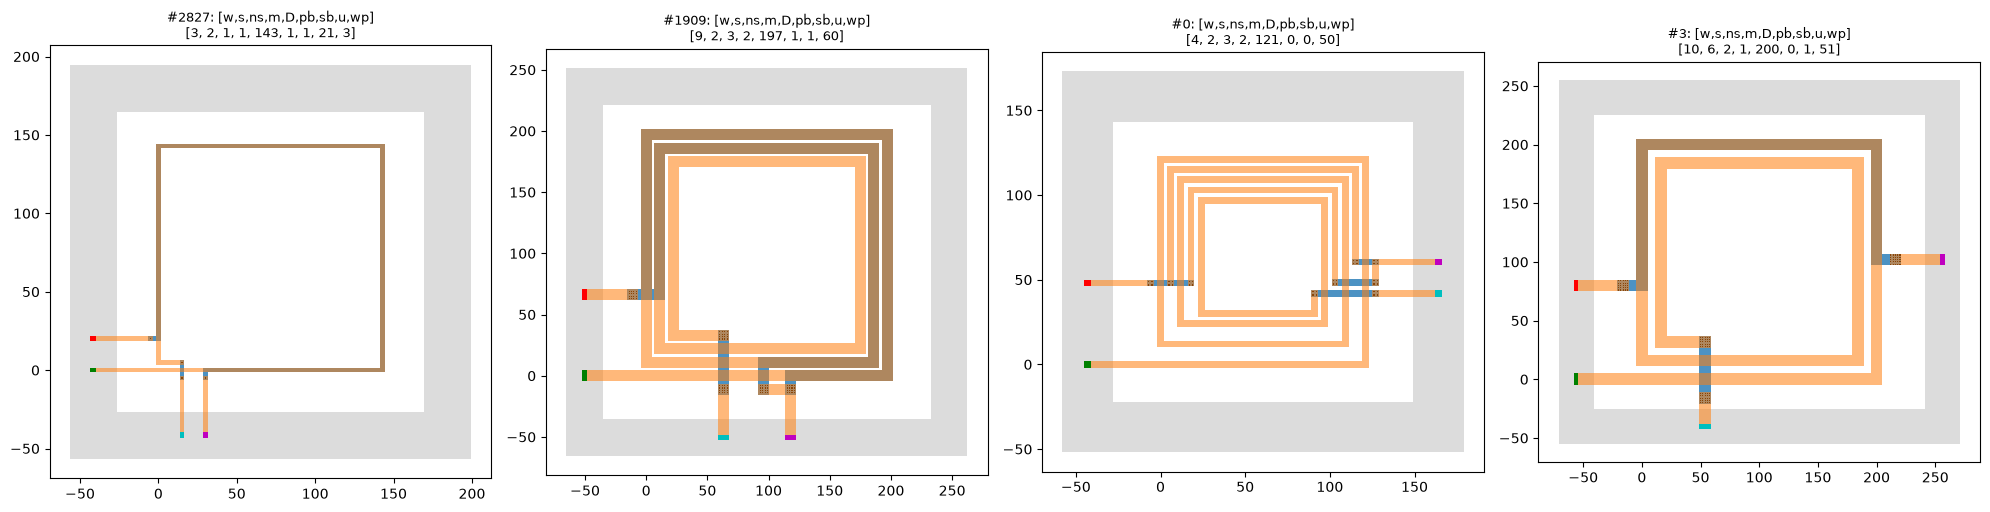

In [6]:
import os, sys, json, glob, inspect, ast
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
sys.path.insert(0, os.getcwd())
import gdspy
from matplotlib.patches import Polygon
import xfmr_gen as XG

def info_geo(i):
    return ast.literal_eval(open(f'INFO/{i}.log').read().split('\n')[0])

# examples taken from the data set: best stacked ns=1 layout, high-coupling ns=3 layout, interleaved, ns=2 stacked
pick = [2827, 1909]
pick.append(next(i for i in range(1500) if os.path.exists(f'INFO/{i}.log') and info_geo(i)[6] == 0))
pick.append(next(i for i in range(1500) if os.path.exists(f'INFO/{i}.log') and info_geo(i)[6] == 1 and info_geo(i)[2] == 2))
col = {XG.M4: ('#bbb', .5), XG.TM1: ('tab:blue', .8), XG.TM2: ('tab:orange', .55), XG.TV2: ('k', 1)}
col.update({l: (c, 1) for l, c in zip(XG.PORT_LAYERS, 'rmgc')})
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
for ax, i in zip(axs, pick):
    g = info_geo(i)
    cell = gdspy.Cell(f'nb_{i}', exclude_from_current=True)
    cell.add(XG.create_xfmr(*g))
    for l in (XG.TM1, XG.TM2): XG.merge_layer(cell, l)
    for (l, d), ps in sorted(cell.get_polygons(by_spec=True).items()):
        for p in ps: ax.add_patch(Polygon(p, closed=True, fc=col.get(l, ('y', 1))[0], ec='none', alpha=col.get(l, ('y', 1))[1]))
    ax.autoscale(); ax.set_aspect('equal'); ax.set_title(f'#{i}: [w,s,ns,m,D,pb,sb,u,wp]\n{g}', fontsize=9)
plt.tight_layout(); plt.show()

## 3. Massive EM Data Generation

### 3.1 openEMS on Ray

`simulator_openems.py` converts a GDS layout to a CSXCAD model of the SG13G2 stack (`SG13G2.xml`), places the lumped ports of layers 201 to 204 and runs the FDTD
simulation from 0 to 100 GHz (1001 points) for the ports of the layout. The result is a Touchstone file `SPData/{index}.s4p`
(port order 1 = P, 2 = $\bar P$, 3 = S, 4 = $\bar S$; the spirals are two-port).

`emx_sim.py` distributes the layouts over a Ray cluster: every layout is one task with 4 threads. The scripts are:

In [7]:
%%writefile simulator_openems.py
# N-port openEMS simulation of a transformer (4 ports) or spiral (2 ports), adapted from TIA_Diff_work.
# No symmetry is assumed: every port is excited once (N FDTD runs), the S-matrix is written as touchstone.
# Env: EM_MARGIN (um), EM_ENERGY (dB end criterion), EM_SKIP_PORT=k skips the excitation of port k (S column by reciprocity, S_kk by energy balance).
# Usage: python simulator_openems.py -g x.gds -s x.s4p -x SG13G2.xml -m name -r workdir [--nports 4] [--preview]
import os
import sys
import argparse

parser = argparse.ArgumentParser("parser")
parser.add_argument('-g', '--gds')
parser.add_argument('-s', '--snp')
parser.add_argument('-x', '--xml')
parser.add_argument('-m', '--model')
parser.add_argument('-r', '--script')
parser.add_argument('--nports', type=int, default=4)
parser.add_argument('--preview', action='store_true')
args = parser.parse_args()

sys.path.insert(0, os.path.abspath(os.path.join(args.script, 'modules')))

import modules.util_stackup_reader as stackup_reader
import modules.util_gds_reader as gds_reader
import modules.util_utilities as utilities
import modules.util_simulation_setup as simulation_setup
import modules.util_meshlines as util_meshlines

from openEMS import openEMS
import numpy as np
import skrf as rf

preview_only = args.preview
postprocess_only = False

gds_filename = args.gds
XML_filename = args.xml
preprocess_gds = True
merge_polygon_size = 1.5
script_path = args.script
model_basename = args.model

sim_path = os.path.join('/tmp/ray_cache', 'TIADN_' + model_basename + '_sim')
print('Simulation data directory: ', sim_path)
os.chdir(script_path)

unit = 1e-6
margin = float(os.environ.get('EM_MARGIN', 200))

fstart = 0
fstop = 100e9
numfreq = 1001

refined_cellsize = 1.0
Boundaries = ['PEC', 'PEC', 'PEC', 'PEC', 'PEC', 'PEC']
cells_per_wavelength = 20
energy_limit = float(os.environ.get('EM_ENERGY', -50))
SKIP = int(os.environ.get('EM_SKIP_PORT', 0))   # port whose excitation is skipped (4-port only); its column is estimated

NPORTS = args.nports
simulation_ports = simulation_setup.all_simulation_ports()
for pn in range(1, NPORTS + 1):
	simulation_ports.add_port(simulation_setup.simulation_port(portnumber=pn, voltage=1, port_Z0=50, source_layernum=200 + pn, from_layername='Metal4', to_layername='TopMetal2', direction='z'))

materials_list, dielectrics_list, metals_list = stackup_reader.read_substrate(XML_filename)
layernumbers = metals_list.getlayernumbers()
layernumbers.extend(simulation_ports.portlayers)

allpolygons = gds_reader.read_gds(gds_filename, layernumbers, purposelist=[0], metals_list=metals_list, preprocess=preprocess_gds, merge_polygon_size=merge_polygon_size)

wavelength_air = 3e8 / fstop / unit
max_cellsize = (wavelength_air) / (np.sqrt(materials_list.eps_max) * cells_per_wavelength)

FDTD = openEMS(EndCriteria=np.exp(energy_limit / 10 * np.log(10)))
FDTD.SetGaussExcite((fstart + fstop) / 2, (fstop - fstart) / 2)
FDTD.SetBoundaryCond(Boundaries)

EXC = [pn for pn in range(1, NPORTS + 1) if pn != SKIP]
for pn in EXC:
	FDTD = simulation_setup.setupSimulation([pn],
											simulation_ports,
											FDTD,
											materials_list,
											dielectrics_list,
											metals_list,
											allpolygons,
											max_cellsize,
											refined_cellsize,
											margin,
											unit,
											xy_mesh_function=util_meshlines.create_xy_mesh_from_polygons)
	simulation_setup.runSimulation([pn], FDTD, sim_path, model_basename, preview_only, postprocess_only)

if not preview_only:
	print('Begin data evaluation')
	f = np.linspace(fstart, fstop, numfreq)
	s = np.zeros((numfreq, NPORTS, NPORTS), dtype=complex)
	for j in EXC:
		for i in range(1, NPORTS + 1):
			s[:, i - 1, j - 1] = utilities.calculate_Sij(i, j, f, sim_path, simulation_ports)
	if SKIP:
		k, p = SKIP - 1, {0: 1, 1: 0, 2: 3, 3: 2}[SKIP - 1]   # p = the other end of the same winding
		for i in range(NPORTS):
			if i != k:
				s[:, i, k] = s[:, k, i]   # reciprocity
		# |S_kk|^2 from energy balance with the partner's loss, phase of the partner's S_pp
		off = sum(np.abs(s[:, i, k]) ** 2 for i in range(NPORTS) if i != k)
		loss_p = 1 - (np.abs(s[:, :, p]) ** 2).sum(axis=1)
		s[:, k, k] = np.sqrt(np.clip(1 - off - loss_p, 0, 1)) * np.exp(1j * np.angle(s[:, p, p]))
	ext = f'.s{NPORTS}p'
	rf.Network(frequency=rf.Frequency.from_f(f, unit='hz'), s=s, z0=50).write_touchstone(
		args.snp[:-len(ext)] if args.snp.endswith(ext) else args.snp, form='ri')

Overwriting simulator_openems.py


In [8]:
%%writefile emx_sim.py
# Distributed openEMS runs (transformers: 4 ports, spirals: 2 ports, from INFO/{i}.log line 2) via Ray.
# Usage: python emx_sim.py start end            (index range)
#        python emx_sim.py --list i1,i2,...      (explicit indices, e.g. verification layouts; @file reads them from a file)
# EXCLUDE_IPS="ip1,ip2" keeps tasks away from broken/unreachable nodes; a failed task does not abort the batch.
import ray
import os
import socket
import sys

DATA_PATH = os.path.dirname(os.path.abspath(__file__))
NTHREADS = os.environ.get("OPENEMS_THREADS", "4")
EM_ENV = {k: os.environ[k] for k in ('EM_MARGIN', 'EM_ENERGY', 'EM_SKIP_PORT') if k in os.environ}
OUTDIR = os.environ.get('EM_OUTDIR', f'{DATA_PATH}/SPData')
TAG = os.environ.get('EM_TAG', '')
ray.init(address=os.environ.get("RAY_ADDRESS"), runtime_env={"env_vars": {"OPENEMS_THREADS": NTHREADS, **EM_ENV}})

excl = {socket.gethostbyname(h.strip()) for h in os.environ.get("EXCLUDE_IPS", "").split(',') if h.strip()}
bad = [n['NodeID'] for n in ray.nodes() if n['Alive'] and n['NodeManagerAddress'] in excl]
opts = dict(num_cpus=int(NTHREADS), max_retries=3)
if bad:
	opts['label_selector'] = {'ray.io/node-id': f"!in({','.join(bad)})"}
	print('excluding nodes', sorted(excl))


def nports(index):
	lines = open(f'{DATA_PATH}/INFO/{index}.log').read().split()
	return 2 if 'spiral' in lines else 4


def out_name(index):
	return f"{OUTDIR}/{index}.s{nports(index)}p"


@ray.remote
def emx_task(index):
	d = DATA_PATH
	out = out_name(index)
	if os.path.exists(out):
		return True
	m = f"{index}{TAG}"
	os.makedirs(os.path.dirname(out), exist_ok=True)
	os.system(f"{sys.executable} {d}/simulator_openems.py -g {d}/GDS/{index}.gds -s {out} -x {d}/SG13G2.xml -m {m} -r {d}"
			  f" --nports {nports(index)} > {d}/EMLOG/{m}.log 2>&1")
	os.system(f"rm -rf /tmp/ray_cache/TIADN_{m}_sim")
	return os.path.exists(out)


if '--list' in sys.argv:
	arg = sys.argv[sys.argv.index('--list') + 1]
	indices = [int(i) for i in (open(arg[1:]).read() if arg.startswith('@') else arg).split(',')]
else:
	indices = list(range(int(sys.argv[1]) if len(sys.argv) > 1 else 0, int(sys.argv[2]) if len(sys.argv) > 2 else 1500))
# Bounded in-flight window: submitting thousands at once made worker startup time out (RaySystemError).
WINDOW = int(os.environ.get("EMX_WINDOW", "30"))
todo = [i for i in indices if not os.path.exists(out_name(i))]
total = len(indices)
refs, result, pending = {}, {i: True for i in indices if i not in todo}, []
tries = {}
while todo or pending:
	while todo and len(pending) < WINDOW:
		i = todo.pop(0)
		r = emx_task.options(**opts).remote(i)
		refs[r] = i
		pending.append(r)
	done, pending = ray.wait(pending, num_returns=1)
	idx = refs[done[0]]
	try:
		result[idx] = ray.get(done[0])
	except Exception as e:
		tries[idx] = tries.get(idx, 0) + 1
		print(f'task {idx} failed (try {tries[idx]}): {type(e).__name__}: {str(e)[:300]}', flush=True)
		if tries[idx] < 3:
			todo.append(idx)
			continue
		result[idx] = False
	if len(result) % 50 == 0:
		print(f'{len(result)}/{total} finished, {sum(result.values())} ok', flush=True)

with open(os.path.join(DATA_PATH, 'Failed_List.txt'), 'a') as fi:
	for i in sorted(result):
		if not result[i]:
			fi.write(str(i) + '\n')
print("Done", sum(result.values()), "/", len(result))

Overwriting emx_sim.py


The commands that generated the data (the layouts of a batch are written first, then the simulations are launched; a layout whose `.s4p` exists is skipped, so a batch can be restarted at any time):

```bash
export RAY_AUTH_MODE=token RAY_ADDRESS=<head-node>:6379
export OPENEMS_THREADS=4 EMX_WINDOW=30 EM_ENERGY=-40 EM_MARGIN=100 EM_SKIP_PORT=2
python xfmr_gen.py 1500 2500 1 --geos results/new_geos.json     # layouts 1500..2499 (batch 1, section 3.3)
python xfmr_gen.py 2500 3000 1 --geos results/focus_geos.json   # layouts 2500..2999 (batch 2, section 3.3)
python emx_sim.py --list @results/main_batch_order.txt   # batch 1, in order of priority
python emx_sim.py --list @results/focus_order.txt        # batch 2
```

### 3.2 A faster EM setting

A default simulation of one transformer takes too long for 1000 layouts. Three changes shorten it to about 15 % of the time:

* the FDTD end criterion is relaxed from -50 dB to -40 dB (`EM_ENERGY`),
* the boundary margin around the layout is reduced from 200 $\mu$m to 100 $\mu$m (`EM_MARGIN`),
* only three of the four ports are excited (`EM_SKIP_PORT=2`); the column of the skipped port follows from reciprocity and the missing $S_{22}$ from the passivity of the lossy network.

The same layout was simulated with both settings; the differences are listed here.

In [9]:
print(open('results/em_fast_validation.txt').read() if os.path.exists('results/em_fast_validation.txt') else 'not available')
print(len(glob.glob('GDS/*.gds')), 'GDS layouts,', len(glob.glob('SPData/*.s4p')), 'transformer S4P files')

Layout #1 [w,s,ns,m,D,pb,sb,u] = [4, 6, 1, 1, 78, 0, 0, 50]
default: end criterion -50 dB, margin 200 um, 4 excitations (1.13 M cells, 217617 iterations in total, FDTD 903 s)
fast   : end criterion -40 dB, margin 100 um, 3 excitations (port 2 skipped; 1.04 M cells, 101655 iterations, FDTD 127 s = 0.14x)

figure (10 GHz)   default   fast     error
Lp                0.276 nH  0.274 nH  -0.7 %
Ls                0.350 nH  0.347 nH  -0.9 %
k (P,Sbar)       -0.022    -0.022     0.000 (absolute)
Qp                5.50      5.71      +3.8 %
Qs                6.41      6.57      +2.5 %
SRF               61 GHz    60 GHz    -1.6 %
mean |dS| 0.0037, max |dS| 0.090 (single point, S22 estimate at high frequency)
All figure errors <= 5 %  -> fast setting accepted.

3005 GDS layouts, 979 transformer S4P files


### 3.3 Which layouts are simulated?

A random layout of 9 parameters is mostly useless for a TIA: most random transformers have a small coupling, a very large inductance or a
self-resonance far below 26 GHz. Two batches were simulated.

**Batch 1 (indices 1500 to 2499).** 1000 layouts chosen from a pool of random layouts and simulated in the order of their closeness to the (Lp, Ls) values that an
ideal-transformer co-design asked for; every fifth layout is random to keep the whole space covered. The layouts were ranked with a
quasi-static partial-inductance model (`xfmr_model.py`) calibrated on the first EM results.

**Batch 2 (indices 2500 to 2999).** After batch 1 it was clear that the coupling of a planar transformer in this stack saturates near $k \approx 0.5$ for single-turn layouts, and that a
good co-design needs $L_p \approx 0.5$ nH and $L_s \approx 0.5$ to 0.7 nH. Batch 2 therefore contains 350 layouts chosen from a pool of 30000 by the calibrated model (high $k$, $L_p$ and $L_s$ close to the co-design targets,
mostly stacked) and 150 exploration layouts spread over `ns` = 1, 2, 3, which are simulated last. The EM data of this notebook are the layouts with the indices 1500 and above.

In [10]:
%%writefile xfmr_model.py
# Quasi-static (partial-inductance) estimate of Lp, Ls, k of a layout from xfmr_gen.py geometry.
# Filament model: every centre-line segment carries its current, TM1 bars lie DZ below TM2. Parallel segments only (orthogonal M = 0).
# The distance of two segments is the geometric mean distance (GMD) of their strip cross-sections (widths wp / w).
import os
import sys
import numpy as np
import xfmr_gen as X

MU0 = 4e-7 * np.pi
DZ = 4.0        # um, TM2 -> TM1 centre distance
TH = 3.0        # um, metal thickness used in the self term


def paths(w, s, ns, m, D, pb=0, sb=0, u=50, wp=None):
	"""-> (P segments, S segments); segment = (x0, y0, x1, y1, z, current weight, track width).
	P current flows P -> Pbar, S current S -> Sbar."""
	wp = w if wp is None else wp
	fr = X.frame(w, s, ns, m, D, pb, sb, u, wp)
	if sb == 2:        # full-overlap loops: S clockwise (TM2) from S to Sbar, P counter-clockwise (TM1) from P to Pbar
		x1, x2, dx, yj, ypb = fr['x1'], fr['x2'], fr['dx'], fr['yj'], fr['ypb']
		sp = [(x1, ypb), (x1, 0), (0, 0), (0, D), (D, D), (D, 0), (x2, 0), (x2, ypb)]
		S = [(*a, *b, 0.0, 1.0, w) for a, b in zip(sp[:-1], sp[1:])]
		pp = [((x2 + dx, ypb), (x2 + dx, yj), 0.0), ((x2 + dx, yj), (x2, yj), -DZ), ((x2, yj), (x2, 0), -DZ), ((x2, 0), (D, 0), -DZ),
			  ((D, 0), (D, D), -DZ), ((D, D), (0, D), -DZ), ((0, D), (0, 0), -DZ), ((0, 0), (x1, 0), -DZ), ((x1, 0), (x1, yj), -DZ),
			  ((x1, yj), (x1 - dx, yj), -DZ), ((x1 - dx, yj), (x1 - dx, ypb), 0.0)]
		return [(*a, *b, z, 1.0, wp) for a, b, z in pp], S
	p, o, q, oe, y_u, y_e, y_pe = fr['p'], fr['o'], fr['q'], fr['oe'], fr['y_u'], fr['y_e'], fr['y_pe']
	S, P = [], []
	pts = [(0.0, 0.0)]
	for t, ot in enumerate(o):
		nxt = o[t + 1] if t + 1 < len(o) else oe
		pts += [(D - ot, ot), (D - ot, D - ot), (ot, D - ot), (ot, nxt)]
	pts += [(fr['x_se'], oe)] if sb else [(D - oe, oe), (D - oe, y_e)]
	for a, b in zip(pts[:-1], pts[1:]):
		S.append((*a, *b, 0.0, 1.0, w))
	if sb:
		S.append((fr['x_se'], oe, fr['x_se'], -p, -DZ, 1.0, w))             # Sbar underpass (TM1), downwards
	else:
		S.append((D - oe, y_e, D + p, y_e, -DZ, 1.0, w))                   # Sbar underpass (TM1)
	for k, qk in enumerate(q):
		zr = -DZ if sb else 0.0                                     # stacked variant: rings on TM1 below the secondary
		if pb == 0:
			r = [(qk, y_u), (qk, D - qk), (D - qk, D - qk), (D - qk, y_pe[k])]
		else:
			r = [(qk, y_u), (qk, D - qk), (D - qk, D - qk), (D - qk, qk), (fr['x_pe'][k], qk)]
		for a, b in zip(r[:-1], r[1:]):
			P.append((*a, *b, zr, 1.0 / m, wp))
		if pb == 0:                                                 # Pbar underpass (TM1)
			P.append((D - qk, y_pe[k], D + p, y_pe[k], -DZ, 1.0 / m, wp))
		else:
			P.append((fr['x_pe'][k], qk, fr['x_pe'][k], -p, -DZ, 1.0 / m, wp))
	for j in range(m - 1):                                          # TM2 strap that merges the ring ends
		if pb == 0:
			P.append((D + p, y_pe[j + 1], D + p, y_pe[j], 0.0, (m - 1 - j) / m, wp))
		else:
			P.append((fr['x_pe'][j + 1], -p, fr['x_pe'][j], -p, 0.0, (m - 1 - j) / m, wp))
	# P bar (TM1): current of ring j enters at x = q_j, so the weight decreases inwards
	xs = [-p] + sorted(q)
	for j in range(len(q)):
		P.append((xs[j], y_u, xs[j + 1], y_u, -DZ, 1.0 - j / m, wp))
	# port leads (TM2): current enters at P / S and leaves at Pbar / Sbar
	P.append((fr['xpl'], y_u, -p, y_u, 0.0, 1.0, wp))
	S.append((fr['xpl'], 0.0, 0.0, 0.0, 0.0, 1.0, w))
	P.append((D + p, y_pe[0], fr['xpr'], y_pe[0], 0.0, 1.0, wp) if pb == 0 else (fr['x_pe'][0], -p, fr['x_pe'][0], fr['ypb'], 0.0, 1.0, wp))
	S.append((fr['x_se'], -p, fr['x_se'], fr['ypb'], 0.0, 1.0, w) if sb else (D + p, y_e, fr['xpr'], y_e, 0.0, 1.0, w))
	return P, S


def _G(u, d):
	return u * np.arcsinh(u / d) - np.sqrt(u * u + d * d)


def _phi(t, z):
	r = t * t + z * z + 1e-18
	return 0.25 * r * np.log(r) - 0.25 * r - 0.5 * t * t + z * t * np.arctan(t / z) - 0.5 * z * z * np.log(r)


def gmd(wa, wb, lat, z):
	"""Geometric mean distance [um] of two strips: widths wa, wb, centre offset lat (lateral) and z (vertical)."""
	z = max(abs(z), 1e-6)
	b0 = lat - wb / 2                      # strip a spans [-wa/2, wa/2], strip b spans [b0, b0 + wb]
	f = lambda t: _phi(t, z)
	ln_gmd = (f(wa / 2 - b0) - f(-wa / 2 - b0) - f(wa / 2 - b0 - wb) + f(-wa / 2 - b0 - wb)) / (wa * wb)
	return float(np.exp(ln_gmd))


def mutual(a, b):
	"""Partial mutual inductance [H] of two segments (signed by direction and weights)."""
	ax0, ay0, ax1, ay1, za, ia, wa = a
	bx0, by0, bx1, by1, zb, ib, wb = b
	adx, ady, bdx, bdy = ax1 - ax0, ay1 - ay0, bx1 - bx0, by1 - by0
	horiz_a, horiz_b = abs(adx) > abs(ady), abs(bdx) > abs(bdy)
	if horiz_a != horiz_b:
		return 0.0
	if horiz_a:
		sa, sb_ = np.sign(adx), np.sign(bdx)
		a1, a2 = sorted((ax0, ax1)); b1, b2 = sorted((bx0, bx1)); lat = by0 - ay0
	else:
		sa, sb_ = np.sign(ady), np.sign(bdy)
		a1, a2 = sorted((ay0, ay1)); b1, b2 = sorted((by0, by1)); lat = bx0 - ax0
	d = gmd(wa, wb, lat, za - zb)
	g = _G(a2 - b1, d) - _G(a1 - b1, d) - _G(a2 - b2, d) + _G(a1 - b2, d)
	return MU0 / (4 * np.pi) * g * 1e-6 * sa * sb_ * ia * ib


def selfl(seg):
	l = (abs(seg[2] - seg[0]) + abs(seg[3] - seg[1])) * 1e-6
	if l == 0:
		return 0.0
	wt = (seg[6] + TH) * 1e-6
	return MU0 / (2 * np.pi) * l * (np.log(2 * l / wt) + 0.5 + 0.2235 * wt / l) * seg[5] ** 2


def lmat(geo):
	P, S = paths(*geo)
	def tot(A, B):
		if A is B:
			return sum(selfl(a) for a in A) + sum(mutual(A[i], A[j]) for i in range(len(A)) for j in range(len(A)) if i != j)
		return sum(mutual(a, b) for a in A for b in B)
	return tot(P, P), tot(S, S), tot(P, S)


def k_model(geo):
	"""Lp, Ls [H] and k(P,Sbar) (positive for the opposite winding senses of xfmr_gen)."""
	lp, ls, m = lmat(geo)
	return lp, ls, -m / np.sqrt(lp * ls)


if __name__ == '__main__':
	data = [([4, 6, 1, 1, 78, 0, 0, 50], .275, .349, -.022), ([4, 5, 1, 1, 95, 1, 0, 46], .340, .434, .219), ([6, 6, 1, 1, 93, 0, 0, 50], .305, .392, -.016),
			([4, 2, 3, 2, 121, 0, 0, 50], .381, 2.089, .317), ([6, 4, 1, 1, 78, 1, 1, 47], .239, .270, .184)]
	for g, lp, ls, k in data:
		a, b, c = k_model(g)
		print(g, f'EM Lp {lp:.3f} Ls {ls:.3f} k {k:+.3f} | model Lp {a*1e9:.3f} Ls {b*1e9:.3f} k {c:+.3f}')

Overwriting xfmr_model.py


In [11]:
%%writefile xfmr_select_batch2.py
# Second EM batch (indices 2500..2999): 500 layouts in the model-optimal region of the transformer space with the port order
# P next to S and Pbar next to Sbar (interleaved sb=0 and stacked sb=1 types, independent secondary / primary widths w / wp).
# Model (xfmr_model.py, calibrated with EM: Lp x1.05, Ls x1.24, k -0.03 stacked / -0.01 interleaved, DZ = 6) scores the layouts by the distance
# of (Lp, Ls) to the ideal-design region (Lp 0.45-0.6 nH, Ls 0.3-0.55 nH) and by k; 70 % core set (best score, one layout per
# (w, wp, D) cell) + 30 % exploration (random layouts with k above K_EXPLORE).
# Writes results/focus_geos.json, results/focus_order.txt, results/focus_info.json. Usage: python xfmr_select_batch2.py [n_pool]
import json
import multiprocessing as mp
import os
import random
import sys
import numpy as np
import xfmr_gen as X
import xfmr_model as M

HERE = os.path.dirname(os.path.abspath(__file__))
START, N_SELECT, N_EXPLORE = 2500, 500, 150
K_EXPLORE = 0.35
LP_T, LS_T = 0.50, 0.45          # nH, centre of the ideal-design region
M.DZ = 6.0


def evaluate(geo):
	lp, ls, k = M.k_model(geo)
	return lp * 1.05e9, ls * 1.24e9, k - (0.03 if geo[6] else 0.01)


def score(lp, ls, k):
	return abs(np.log(lp / LP_T)) + 0.7 * abs(np.log(ls / LS_T)) + 4 * np.maximum(0, 0.55 - k)


def select(n_pool):
	random.seed(11)
	rng = np.random.default_rng(1)
	pool = [X.sample_params() for _ in range(n_pool)]
	with mp.Pool(12) as pl:
		ev = np.array(pl.map(evaluate, pool, chunksize=100))
		for _ in range(2):     # refinement: perturbations of the 200 best layouts
			sc = score(ev[:, 0], ev[:, 1], ev[:, 2])
			best = [pool[i] for i in np.argsort(sc)[:200]]
			new = [X.focus_params(best) for _ in range(n_pool // 4)]
			pool += new
			ev = np.vstack([ev, np.array(pl.map(evaluate, new, chunksize=100))])
	lp, ls, k = ev[:, 0], ev[:, 1], ev[:, 2]
	sc = score(lp, ls, k)
	seen, core = set(), []
	for i in np.argsort(sc):
		cell = (pool[i][0], pool[i][8], pool[i][4] // 10, pool[i][6])
		if cell in seen:
			continue
		seen.add(cell)
		core.append(int(i))
		if len(core) == N_SELECT - N_EXPLORE:
			break
	rest = [i for i in np.where(k >= K_EXPLORE)[0] if i not in set(core)]
	expl = [int(i) for i in rng.choice(rest, N_EXPLORE, replace=False)]
	seq = core + expl
	geos = [pool[i] for i in seq]
	json.dump(geos, open(f'{HERE}/results/focus_geos.json', 'w'))
	open(f'{HERE}/results/focus_order.txt', 'w').write(','.join(str(START + j) for j in range(len(seq))))
	nc = len(core)
	info = dict(n_pool=len(pool), n_core=nc, n_explore=len(expl), start=START,
				core_k_percentiles=[float(v) for v in np.percentile(k[core], [0, 50, 100])],
				core_lp_nh=[float(np.percentile(lp[core], q)) for q in (5, 50, 95)], core_ls_nh=[float(np.percentile(ls[core], q)) for q in (5, 50, 95)],
				n_stacked=int(sum(g[6] for g in geos)), n_wp_ne_w=int(sum(g[8] != g[0] for g in geos)))
	json.dump(info, open(f'{HERE}/results/focus_info.json', 'w'), indent=1)
	print(info)
	for i in core[:10]:
		print(pool[i], np.round([lp[i], ls[i], k[i]], 3))


if __name__ == '__main__':
	select(int(sys.argv[1]) if len(sys.argv) > 1 else 20000)

Overwriting xfmr_select_batch2.py


In [12]:
if os.path.exists('results/focus_info.json'):
    print(json.dumps(json.load(open('results/focus_info.json')), indent=1)[:1200])

{
 "n_pool": 30000,
 "n_core": 350,
 "n_explore": 150,
 "start": 2500,
 "core_k_percentiles": [
  0.43118541629137574,
  0.49494724637935206,
  0.6104681304707177
 ],
 "core_lp_nh": [
  0.4508905465394994,
  0.5003897786378155,
  0.570022035655562
 ],
 "core_ls_nh": [
  0.7076384733493171,
  0.8179408170236866,
  1.159153365016082
 ],
 "n_stacked": 401,
 "n_wp_ne_w": 416
}


## 4. What Do the EM Data Say?

Every S4P file is reduced to figures at 10 GHz from the two-port $Z$-matrix of the transformer between P and $\bar S$ (the other ports grounded):
$L_p$, $L_s$, $k = M / \sqrt{L_p L_s}$, the quality factors $Q_p$, $Q_s$ and the self-resonance frequency (the first frequency at which $L_p$ turns negative).
Loading 1000 files takes a few minutes, so the figures are cached in `results/xfmr_figures.npz`.

In [13]:
%%writefile surrogate.py
# Surrogates for the passive devices of the transformer-RGC TIA:
#   kind 'xfmr'  : transformer geometry [w, s, ns, m, D, pb, sb, u, wp] -> 4-port S (this work, s4p; reciprocity only -> 10 entries)
#   kind 'spiral': spiral geometry [w, s, n, Dx, Dy]   -> 2-port S (data reused from ../TIA_work, s2p; 3 entries)
# Models: plain MLP or pre-LN residual MLP (ResMLP, best in TIA_Diff_work/arch_compare), ensemble average.
# Training follows the T-coil notebook (min-max [-1,1] normalisation, L1 loss, AdamW, OneCycle, 70/20/10 split).
# Usage: python surrogate.py --kind xfmr|spiral [--arch res|mlp] [--epochs 2000] [--ens 5] [--out models/xfmr.pt]
import argparse
import ast
import copy
import glob
import json
import os
import time
import numpy as np
import skrf as rf
import torch
import torch.nn as nn

HERE = os.path.dirname(os.path.abspath(__file__))
F_IDX = np.arange(10, 1001, 10)          # 1..100 GHz (1 GHz step) of the 1001-point EM sweep
FREQ = F_IDX * 1e8
N_F = len(F_IDX)
K10 = int(np.argmin(np.abs(FREQ - 10e9)))


# ----------------------------------------------------------------------------- geometry features
def track_offsets(w, s, ns, m, stack=0, wp=None):
	"""Same track order as xfmr_gen.offsets: S0, P0, S1, P1, ..., remaining S turns (stack = 1: P rings under S0, S1)."""
	p = max(w, w if wp is None else wp) + s
	if stack:
		return p, [t * p for t in range(int(ns))], [k * p for k in range(int(m))]
	kinds = []
	for t in range(int(ns)):
		kinds.append('S')
		if t < m:
			kinds.append('P')
	return p, [i * p for i, c in enumerate(kinds) if c == 'S'], [i * p for i, c in enumerate(kinds) if c == 'P']


def xfmr_features(geo):
	"""Raw geometry (pb = Pbar exit mode: right edge / bottom edge, u = Pbar end position) + winding lengths of the
	secondary (ns turns + partial turn) and of one primary ring, TM1 exit lengths, area, inner hole (same frame as xfmr_gen.frame)."""
	rows = []
	for row in np.atleast_2d(np.asarray(geo, float)):
		w, s, ns, m, D, pb, sb, u = row[:8]
		wp = row[8] if len(row) > 8 else w
		if sb == 2:        # full-overlap loops: both windings are one turn of length 4 D, terminal leads ~ 40 um each
			rows.append([w, s, 1, 1, D, 1, 2, u, wp, 4 * D, 4 * D, 4 * D / w, 4 * D / wp, wp / w, D * D, (D - max(w, wp)) ** 2, 1, 0, 0, 0])
			continue
		p, o, q = track_offsets(w, s, ns, m, sb, wp)
		oe = o[-1] + p
		y_u, y_e = oe + 3 * p, oe + 2 * p
		xe = u / 100 * D
		ls = sum(4 * (D - 2 * ot) for ot in o) + ((xe - 3 * p - oe) if sb else (D - 2 * oe) + (y_e - oe))   # full turns + partial turn
		lp = float(np.mean([(D - qk - y_u) + (D - 2 * qk)                              # left edge up, top edge
							+ ((D - qk - xe) if not pb else (D - 2 * qk) + (D - qk - xe))   # right edge (+ bottom edge back to x_pe)
							for qk in q]))
		hole = D - 2 * oe
		rows.append([w, s, ns, m, D, pb, sb, u, wp, ls, lp, ls / w, lp / (m * wp), wp / w, D * D, hole * hole, ns / m, oe, y_u, y_e])
	return np.array(rows)



def spiral_length(w, s, n, Dx, Dy):
	"""TopMetal2 centre-line length of the spiral (same path as spiral_gen.spiral_points)."""
	p = w + s
	pts = [(0.0, 0.0)]
	for t in range(int(n)):
		pts += [(Dx - t * p, t * p), (Dx - t * p, Dy - t * p), (t * p, Dy - t * p), (t * p, (t + 1) * p)]
	return float(np.abs(np.diff(np.array(pts), axis=0)).sum())


def spiral_features(geo):
	g = np.atleast_2d(np.asarray(geo, float))
	w, s, n, Dx, Dy = g.T
	p = w + s
	length = np.array([spiral_length(*row) for row in g])
	return np.column_stack([w, s, n, Dx, Dy, length, length / w, Dx * Dy, (Dx - 2 * n * p) * (Dy - 2 * n * p)])


# ----------------------------------------------------------------------------- device figures
def spiral_figures(f, s):
	"""Series-branch L/Q of the pi-equivalent (Zs = -1/Y21) and SRF of port 1 with port 2 grounded."""
	y = rf.network.s2y(s, 50)
	zs = -1 / y[:, 1, 0]
	k10 = np.argmin(np.abs(f - 10e9))
	L10 = zs[k10].imag / (2 * np.pi * f[k10])
	q = np.where(zs.real > 0.05, zs.imag / np.maximum(zs.real, 0.05), 0.0)
	x11 = (1 / y[:, 0, 0]).imag
	cross = np.where((x11[:-1] > 0) & (x11[1:] <= 0))[0]
	srf = f[cross[0]] if len(cross) else f[-1]
	ok = f < srf
	return dict(L10=L10, Q10=q[k10], Qmax=q[ok].max() if ok.any() else 0.0, SRF=srf)


def xfmr_z2(s):
	"""(F,4,4) -> Z (F,2,2) of the 2-port (P, Sbar) = dotted ends (P->Pbar and S->Sbar circulate oppositely), Pbar and S grounded."""
	y = rf.network.s2y(s, 50)[:, [0, 3]][:, :, [0, 3]]
	return np.linalg.inv(y)


def xfmr_curves(f, s):
	"""Lp, Ls [H], k, Qp, Qs versus frequency (k > 0 for the dot convention of xfmr_gen)."""
	z = xfmr_z2(s)
	w = 2 * np.pi * f
	Lp, Ls, M = z[:, 0, 0].imag / w, z[:, 1, 1].imag / w, z[:, 0, 1].imag / w
	k = M / np.sqrt(np.abs(Lp * Ls))
	qp = z[:, 0, 0].imag / np.maximum(z[:, 0, 0].real, 1e-3)
	qs = z[:, 1, 1].imag / np.maximum(z[:, 1, 1].real, 1e-3)
	return Lp, Ls, k, qp, qs


def xfmr_figures(f, s):
	Lp, Ls, k, qp, qs = xfmr_curves(f, s)
	k10 = np.argmin(np.abs(f - 10e9))
	cross = np.where((Lp[:-1] > 0) & (Lp[1:] <= 0))[0]
	srf = f[cross[0]] if len(cross) else f[-1]
	return dict(Lp10=Lp[k10], Ls10=Ls[k10], k10=k[k10], n=np.sqrt(abs(Ls[k10] / Lp[k10])), Qp10=qp[k10], Qs10=qs[k10],
				SRF=srf)


# ----------------------------------------------------------------------------- kinds
class Kind:
	def __init__(self, name, nport, ext, data_dir, features, figures, keys):
		self.name, self.nport, self.ext, self.data_dir = name, nport, ext, data_dir
		self.features, self.figures, self.keys = features, figures, keys
		self.sel = [(i, j) for i in range(nport) for j in range(i + 1)]    # lower triangle, reciprocity
		self.ns = len(self.sel)

	def s_to_vec(self, s):
		v = np.stack([s[:, :, i, j] for i, j in self.sel], axis=-1)
		return np.concatenate([v.real, v.imag], axis=-1).reshape(len(s), -1)

	def vec_to_s(self, v):
		v = v.reshape(len(v), N_F, 2 * self.ns)
		c = v[..., :self.ns] + 1j * v[..., self.ns:]
		s = np.zeros((len(v), N_F, self.nport, self.nport), complex)
		for k, (i, j) in enumerate(self.sel):
			s[..., i, j] = c[..., k]
			s[..., j, i] = c[..., k]
		return s

	def broken(self, s):
		"""Open circuit at 1 GHz in one of the windings (e.g. a via dropped by the EM mesh)."""
		if self.nport == 2:
			return np.abs(s[0, 1, 0]) < 0.5
		return np.abs(s[0, 1, 0]) < 0.5 or np.abs(s[0, 3, 2]) < 0.5

	def load_dataset(self, data_dir=None, max_index=8000):
		d = data_dir or self.data_dir
		geo, sp, idx = [], [], []
		for fn in glob.glob(f'{d}/SPData/*.{self.ext}'):
			b = os.path.basename(fn)[:-len(self.ext) - 1]
			if not b.isdigit():
				continue
			i = int(b)
			info = f'{d}/INFO/{i}.log'
			if not os.path.exists(info) or i >= max_index:
				continue
			n = rf.Network(fn)
			if len(n.f) != 1001 or not np.all(np.isfinite(n.s)):
				continue
			s = n.s[F_IDX]
			s = 0.5 * (s + np.swapaxes(s, -1, -2))   # enforce reciprocity
			if self.broken(s):
				continue
			g = ast.literal_eval(open(info).readline())
			geo.append(g if len(g) > 8 or self.name != 'xfmr' else g + [g[0]])
			sp.append(s)
			idx.append(i)
		order = np.argsort(idx)
		return np.array(geo, float)[order], np.array(sp)[order], np.array(idx)[order]


KINDS = dict(
	xfmr=Kind('xfmr', 4, 's4p', HERE, xfmr_features, xfmr_figures, ('w', 's', 'ns', 'm', 'D', 'pb', 'sb', 'u', 'wp')),
	spiral=Kind('spiral', 2, 's2p', os.path.join(HERE, '..', 'TIA_work'), spiral_features, spiral_figures,
				('w', 's', 'n', 'Dx', 'Dy')),
)


# ----------------------------------------------------------------------------- networks
class MLP(nn.Module):
	def __init__(self, n_in, n_out, hidden=(256, 512, 1024, 1024), drop=0.05):
		super().__init__()
		layers, d = [], n_in
		for h in hidden:
			layers += [nn.Linear(d, h), nn.SiLU(), nn.Dropout(drop)]
			d = h
		layers.append(nn.Linear(d, n_out))
		self.net = nn.Sequential(*layers)

	def forward(self, x):
		return self.net(x)


class ResBlock(nn.Module):
	def __init__(self, d, drop):
		super().__init__()
		self.ln = nn.LayerNorm(d)
		self.f1 = nn.Linear(d, 2 * d)
		self.f2 = nn.Linear(2 * d, d)
		self.drop = nn.Dropout(drop)

	def forward(self, x):
		return x + self.f2(self.drop(nn.functional.silu(self.f1(self.ln(x)))))


class ResMLP(nn.Module):
	"""Pre-LN residual MLP."""

	def __init__(self, n_in, n_out, width=256, depth=4, drop=0.0):
		super().__init__()
		self.inp = nn.Linear(n_in, width)
		self.blocks = nn.Sequential(*[ResBlock(width, drop) for _ in range(depth)])
		self.ln = nn.LayerNorm(width)
		self.head = nn.Linear(width, n_out)

	def forward(self, x):
		return self.head(self.ln(self.blocks(self.inp(x))))


def build_model(n_in, n_out, cfg, drop=None):
	d = cfg.get('drop', 0.05) if drop is None else drop
	if cfg['arch'] == 'mlp':
		return MLP(n_in, n_out, tuple(cfg['hidden']), d)
	return ResMLP(n_in, n_out, cfg['width'], cfg['depth'], d)


class Surrogate:
	"""Ensemble surrogate. predict(geo (N,5)) -> S (N, 100, nport, nport) at FREQ."""

	def __init__(self, path, device=None):
		ck = torch.load(path, map_location='cpu', weights_only=False)
		self.kind = KINDS[ck['kind']]
		self.device = device or 'cpu'
		self.xmin, self.xmax, self.ymin, self.ymax = (ck[k] for k in ('xmin', 'xmax', 'ymin', 'ymax'))
		self.cfg = ck['cfg']
		self.models = []
		for sd in ck['states']:
			m = build_model(len(self.xmin), len(self.ymin), self.cfg, 0.0)
			m.load_state_dict(sd)
			self.models.append(m.to(self.device).eval())
		self.freq = FREQ

	def predict(self, geo):
		x = (self.kind.features(geo) - self.xmin) / (self.xmax - self.xmin) * 2 - 1
		xt = torch.from_numpy(x).float().to(self.device)
		with torch.no_grad():
			y = np.mean([m(xt).cpu().numpy() for m in self.models], axis=0)
		return self.kind.vec_to_s((y + 1) / 2 * (self.ymax - self.ymin) + self.ymin)


# ----------------------------------------------------------------------------- training
def train_one(xtr, ytr, xva, yva, cfg, epochs, lr, bs, device, seed, log=True):
	"""Returns (best state dict, history of [epoch, train, val])."""
	torch.manual_seed(seed)
	m = build_model(xtr.shape[1], ytr.shape[1], cfg).to(device)
	opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-4)
	sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * int(np.ceil(len(xtr) / bs)))
	crit = nn.L1Loss()
	xtr, ytr, xva, yva = (torch.from_numpy(a).float().to(device) for a in (xtr, ytr, xva, yva))
	best, best_sd, hist = np.inf, None, []
	for ep in range(epochs):
		m.train()
		perm = torch.randperm(len(xtr), device=device)
		for k in range(0, len(xtr), bs):
			b = perm[k:k + bs]
			opt.zero_grad()
			loss = crit(m(xtr[b]), ytr[b])
			loss.backward()
			nn.utils.clip_grad_norm_(m.parameters(), 1.0)
			opt.step()
			sch.step()
		m.eval()
		with torch.no_grad():
			v = crit(m(xva), yva).item()
		hist.append([ep, loss.item(), v])
		if v < best:
			best, best_sd = v, {k: t.detach().cpu().clone() for k, t in m.state_dict().items()}
		if log and (ep % 200 == 0 or ep == epochs - 1):
			print(f'  seed {seed} epoch {ep:5d} train {loss.item():.5f} val {v:.5f} (best {best:.5f})', flush=True)
	return best_sd, hist


def prepare(kind, seed=42):
	"""Dataset, 70/20/10 split and min-max normalisation (statistics from the training split only)."""
	geo, s, idx = kind.load_dataset()
	X, Y = kind.features(geo), kind.s_to_vec(s)
	perm = np.random.default_rng(seed).permutation(len(X))
	ntr, nva = int(0.7 * len(X)), int(0.2 * len(X))
	tr, va, te = perm[:ntr], perm[ntr:ntr + nva], perm[ntr + nva:]
	xmin, xmax = X[tr].min(0), X[tr].max(0)
	xmax = np.where(xmax - xmin < 1e-9, xmin + 1, xmax)
	ymin, ymax = Y[tr].min(0), Y[tr].max(0)
	ymax = np.where(ymax - ymin < 1e-9, ymin + 1, ymax)
	return dict(geo=geo, s=s, idx=idx, tr=tr, va=va, te=te, xmin=xmin, xmax=xmax, ymin=ymin, ymax=ymax,
				xn=(X - xmin) / (xmax - xmin) * 2 - 1, yn=(Y - ymin) / (ymax - ymin) * 2 - 1)


# ----------------------------------------------------------------------------- evaluation
def freq_errors(kind, s_true, s_pred, f=FREQ):
	"""Per-sample error curves over frequency: mean |dS|, plus |dL| in % of L(10 GHz) (both windings for xfmr), |dk|."""
	out = dict(dS=np.abs(s_pred - s_true).mean(axis=(2, 3)))
	if kind.name == 'spiral':
		dL, dQ = [], []
		for a, b in zip(s_true, s_pred):
			za, zb = -1 / rf.network.s2y(a, 50)[:, 1, 0], -1 / rf.network.s2y(b, 50)[:, 1, 0]
			La, Lb = za.imag / (2 * np.pi * f), zb.imag / (2 * np.pi * f)
			Qa = np.where(za.real > 0.05, za.imag / np.maximum(za.real, 0.05), 0.0)
			Qb = np.where(zb.real > 0.05, zb.imag / np.maximum(zb.real, 0.05), 0.0)
			dL.append(np.abs(Lb - La) / abs(La[K10]) * 100)
			dQ.append(np.abs(Qb - Qa))
		out.update(dL=np.array(dL), dQ=np.array(dQ))
	else:
		dLp, dLs, dk = [], [], []
		for a, b in zip(s_true, s_pred):
			ca, cb = xfmr_curves(f, a), xfmr_curves(f, b)
			dLp.append(np.abs(cb[0] - ca[0]) / abs(ca[0][K10]) * 100)
			dLs.append(np.abs(cb[1] - ca[1]) / abs(ca[1][K10]) * 100)
			dk.append(np.abs(cb[2] - ca[2]))
		out.update(dLp=np.array(dLp), dLs=np.array(dLs), dk=np.array(dk))
	return out


def test_metrics(sur, geo, s):
	"""Scalar (figures at 10 GHz) and per-frequency test metrics of a Surrogate on held-out devices."""
	kind = sur.kind
	sp = sur.predict(geo)
	maxe = np.abs(sp - s).max(axis=(1, 2, 3))
	out = dict(kind=kind.name, n_test=len(s), dS_mean=float(np.abs(sp - s).mean()), dS_max_median=float(np.median(maxe)),
			   dS_max_p90=float(np.percentile(maxe, 90)), freq_ghz=(FREQ / 1e9).tolist())
	ft = [kind.figures(FREQ, a) for a in s]
	fp = [kind.figures(FREQ, b) for b in sp]
	for key in ft[0]:
		if key in ('k10',):
			e = np.array([abs(b[key] - a[key]) for a, b in zip(ft, fp)])
			out[f'{key}_abserr_median'], out[f'{key}_abserr_p90'] = float(np.median(e)), float(np.percentile(e, 90))
		else:
			e = np.array([abs(b[key] / a[key] - 1) * 100 for a, b in zip(ft, fp)])
			out[f'{key}_err_median'], out[f'{key}_err_p90'] = float(np.median(e)), float(np.percentile(e, 90))
			out[f'{key}_err_max'] = float(e.max())
	for name, e in freq_errors(kind, s, sp).items():
		out[f'{name}_f_median'] = np.median(e, axis=0).tolist()
		out[f'{name}_f_p90'] = np.percentile(e, 90, axis=0).tolist()
		out[f'{name}_band_mean'] = float(e.mean())
	return out


def report_text(r):
	lines = [f"[{r['kind']}] test samples {r['n_test']} | |dS| mean {r['dS_mean']:.4f}, max-per-sample median "
			 f"{r['dS_max_median']:.4f} p90 {r['dS_max_p90']:.4f}"]
	for key in [k[:-11] for k in r if k.endswith('_err_median') and not k.endswith('abserr_median')]:
		lines.append(f"{key} err %: median {r[key + '_err_median']:.2f} p90 {r[key + '_err_p90']:.2f} "
					 f"max {r[key + '_err_max']:.2f}")
	for key in [k[:-14] for k in r if k.endswith('_abserr_median')]:
		lines.append(f"{key} abs err: median {r[key + '_abserr_median']:.4f} p90 {r[key + '_abserr_p90']:.4f}")
	curves = [k[:-9] for k in r if k.endswith('_f_median')]
	lines.append('over frequency (mean of per-frequency medians): ' +
				 ', '.join(f"{c} {np.mean(r[c + '_f_median']):.4f}" for c in curves))
	return '\n'.join(lines)


def save_checkpoint(path, kind, states, cfg, d):
	os.makedirs(os.path.dirname(path), exist_ok=True)
	torch.save(dict(kind=kind.name, states=states, cfg=cfg, xmin=d['xmin'], xmax=d['xmax'], ymin=d['ymin'],
					ymax=d['ymax'], split=dict(train=d['idx'][d['tr']], val=d['idx'][d['va']], test=d['idx'][d['te']])),
			   path)


def main():
	ap = argparse.ArgumentParser()
	ap.add_argument('--kind', default='xfmr', choices=list(KINDS))
	ap.add_argument('--arch', default='res', choices=['res', 'mlp'])
	ap.add_argument('--epochs', type=int, default=2000)
	ap.add_argument('--ens', type=int, default=5)
	ap.add_argument('--lr', type=float, default=2e-3)
	ap.add_argument('--bs', type=int, default=64)
	ap.add_argument('--hidden', default='256,512,1024,1024')
	ap.add_argument('--width', type=int, default=256)
	ap.add_argument('--depth', type=int, default=4)
	ap.add_argument('--drop', type=float, default=0.05)
	ap.add_argument('--out', default=None)
	a = ap.parse_args()
	kind = KINDS[a.kind]
	out = a.out or f'{HERE}/models/{a.kind}.pt'
	if a.arch == 'mlp':
		cfg = dict(arch='mlp', hidden=[int(h) for h in a.hidden.split(',')], drop=a.drop)
	else:
		cfg = dict(arch='res', width=a.width, depth=a.depth, drop=a.drop)
	device = 'cuda' if torch.cuda.is_available() else 'cpu'

	d = prepare(kind)
	print(f"[{kind.name}] {len(d['geo'])} valid samples, device {device}, cfg {cfg}")
	tr, va, te = d['tr'], d['va'], d['te']
	t0 = time.time()
	states, hists = [], []
	for seed in range(a.ens):
		sd, h = train_one(d['xn'][tr], d['yn'][tr], d['xn'][va], d['yn'][va], cfg, a.epochs, a.lr, a.bs, device, seed)
		states.append(sd)
		hists.append(h)
	save_checkpoint(out, kind, states, cfg, d)
	print(f'training time {time.time() - t0:.0f}s -> {out}')

	r = test_metrics(Surrogate(out), d['geo'][te], d['s'][te])
	r['n_samples'] = len(d['geo'])
	r['cfg'] = cfg
	r['history'] = hists[0]
	report = report_text(r)
	print(report)
	with open(out.replace('.pt', '_report.txt'), 'w') as fo:
		fo.write(report + '\n')
	with open(out.replace('.pt', '_report.json'), 'w') as fo:
		json.dump(r, fo, default=float)


if __name__ == '__main__':
	main()

Overwriting surrogate.py


In [14]:
%%writefile spiral_gen.py
# Parametric 2-port spiral inductor (copied from TIA_work; used here for L1 / Lb verification layouts) for SG13G2:
# TopMetal2 spiral, TopMetal1 underpass, Metal4 ground ring, via ports Metal4->TopMetal2.
# Usage: python spiral_gen.py start end seed
import gdspy
import cairosvg
import os
import random
import sys

TM1, TV2, TM2, M4 = 126, 133, 134, 50
PORT1, PORT2 = 201, 202
GND_MARGIN = 20   # coil bbox to ground ring spacing (um)
GND_WIDTH = 30
PORT_LEN = 4
D_MAX = 150

data_path = os.path.dirname(os.path.abspath(__file__)) + '/'
gdspy.library.use_current_library = False
lib = gdspy.GdsLibrary(name='BatchGen_SpiralL')
lib.precision = 5e-9


def via_array(cx, cy, sx, sy, size=0.9, space=1.06, enc=0.5, layer=TV2):
	nx = int((sx - 2 * enc + space) // (size + space))
	ny = int((sy - 2 * enc + space) // (size + space))
	x0 = cx - (nx * (size + space) - space) / 2
	y0 = cy - (ny * (size + space) - space) / 2
	return [gdspy.Rectangle((x0 + i * (size + space), y0 + j * (size + space)),
							(x0 + i * (size + space) + size, y0 + j * (size + space) + size), layer=layer)
			for i in range(nx) for j in range(ny)]


def via_stack(cx, cy, w):
	return [gdspy.Rectangle((cx - w / 2, cy - w / 2), (cx + w / 2, cy + w / 2), layer=l) for l in (TM1, TM2)] \
		+ via_array(cx, cy, w, w)


def spiral_points(Dx, Dy, p, n):
	pts = [(0.0, 0.0)]
	for t in range(n):
		pts += [(Dx - t * p, t * p), (Dx - t * p, Dy - t * p), (t * p, Dy - t * p), (t * p, (t + 1) * p)]
	return pts


def is_valid(w, s, n, Dx, Dy):
	p = w + s
	return w >= 3 and s >= 2 and n >= 1 and Dx >= (2 * n + 1) * p and Dy >= (2 * n + 1) * p


def create_spiral(w, s, n, Dx, Dy):
	"""Outer terminal (port 1) exits left at y=0; inner terminal (port 2) exits right via TM1 underpass."""
	p = w + s
	shapes = [gdspy.FlexPath(spiral_points(Dx, Dy, p, n), w, gdsii_path=True, layer=TM2).to_polygonset()]

	ex, ey = (n - 1) * p, n * p   # inner end
	xo = Dx + p                   # underpass exit, one pitch outside the outer turn
	shapes += via_stack(ex, ey, w) + via_stack(xo, ey, w)
	shapes.append(gdspy.Rectangle((ex, ey - w / 2), (xo, ey + w / 2), layer=TM1))

	bx0, by0, bx1, by1 = -w / 2, -w / 2, xo + w / 2, Dy + w / 2
	opening = gdspy.Rectangle((bx0 - GND_MARGIN, by0 - GND_MARGIN), (bx1 + GND_MARGIN, by1 + GND_MARGIN))
	outer = gdspy.Rectangle((bx0 - GND_MARGIN - GND_WIDTH, by0 - GND_MARGIN - GND_WIDTH),
							(bx1 + GND_MARGIN + GND_WIDTH, by1 + GND_MARGIN + GND_WIDTH))
	shapes.append(gdspy.boolean(outer, opening, 'not', layer=M4))

	xp1 = bx0 - GND_MARGIN - GND_WIDTH / 2
	xp2 = bx1 + GND_MARGIN + GND_WIDTH / 2
	shapes.append(gdspy.Rectangle((xp1 - PORT_LEN / 2, -w / 2), (0, w / 2), layer=TM2))
	shapes.append(gdspy.Rectangle((xo, ey - w / 2), (xp2 + PORT_LEN / 2, ey + w / 2), layer=TM2))
	shapes.append(gdspy.Rectangle((xp1 - PORT_LEN / 2, -w / 2), (xp1 + PORT_LEN / 2, w / 2), layer=PORT1))
	shapes.append(gdspy.Rectangle((xp2 - PORT_LEN / 2, ey - w / 2), (xp2 + PORT_LEN / 2, ey + w / 2), layer=PORT2))
	return shapes


def sample_params():
	while True:
		# w=2 leaves a single 0.9 um via that the 1 um EM mesh drops (open circuit)
		w = random.randint(3, 10)
		s = random.randint(2, 8)
		n = random.randint(1, 3)
		lo = (2 * n + 1) * (w + s)
		if lo > D_MAX:
			continue
		Dx = random.randint(max(lo, 20), D_MAX)
		Dy = random.randint(max(lo, 20), D_MAX)
		if is_valid(w, s, n, Dx, Dy):
			return [w, s, n, Dx, Dy]


def merge_layer(cell, layer):
	polys = cell.get_polygons((layer, 0))
	if not polys:
		return
	cell.remove_polygons(lambda pts, l, d: l == layer)
	cell.add(gdspy.boolean([gdspy.Polygon(p) for p in polys], None, 'or', layer=layer))


def one_sample(index, geo):
	cell = lib.new_cell(str(index))
	cell.add(create_spiral(*geo))
	for layer in (TM1, TM2):
		merge_layer(cell, layer)

	svg_name = data_path + f'SVG_TEMP/spiral_{os.getpid()}.svg'
	cell.write_svg(svg_name)
	cairosvg.svg2png(bytestring=open(svg_name).read().encode('utf-8'), write_to=data_path + f'PNG/{index}.png', scale=0.1)
	lib.write_gds(data_path + f'GDS/{index}.gds', [cell])
	with open(data_path + f'INFO/{index}.log', 'w') as f:
		f.write(str(list(geo)) + '\nspiral\n')
	lib.remove(cell)


def focus_params(centres):
	"""Active-learning sample: random perturbation of one of the co-design optimum geometries."""
	while True:
		w, s, n, Dx, Dy = random.choice(centres)
		w = min(max(w + random.randint(-2, 2), 3), 10)
		s = min(max(s + random.randint(-2, 2), 2), 8)
		n = min(max(n + random.choice([0, 0, 0, -1, 1]), 1), 3)
		Dx = int(round(Dx * random.uniform(0.75, 1.25)))
		Dy = int(round(Dy * random.uniform(0.75, 1.25)))
		if max(Dx, Dy) <= D_MAX and is_valid(w, s, n, Dx, Dy):
			return [w, s, n, Dx, Dy]


if __name__ == '__main__':
	start_num = int(sys.argv[1]) if len(sys.argv) > 1 else 0
	end_num = int(sys.argv[2]) if len(sys.argv) > 2 else 2000
	random.seed(int(sys.argv[3]) if len(sys.argv) > 3 else 42)
	# optional: co-design result json -> half of the samples are drawn around its top geometries
	centres = None
	if len(sys.argv) > 4:
		import json
		best = json.load(open(sys.argv[4]))
		centres = [[r['params'][k] for k in ('w', 's', 'n', 'Dx', 'Dy')] for r in best['top5']]
	os.chdir(data_path)
	for index in range(start_num, end_num):
		if index % 100 == 0:
			print('Generating sample:', index)
		one_sample(index, focus_params(centres) if centres and index % 2 else sample_params())

Overwriting spiral_gen.py


In [15]:
import surrogate as SU, tia_sim as T
files = sorted(glob.glob('SPData/*.s4p'))
cache = 'results/xfmr_figures.npz'
c = np.load(cache) if os.path.exists(cache) else None
if c is None or len(c['idx']) != len(files):
    geo, s_all, idx = SU.KINDS['xfmr'].load_dataset()
    figs = []
    for s in s_all:
        f = SU.xfmr_figures(SU.FREQ, s)
        figs.append([f['Lp10'] * 1e9, f['Ls10'] * 1e9, f['k10'], f['Qp10'], f['Qs10'], f['SRF'] / 1e9])
    keep = {i: s for i, s in zip(idx, s_all) if int(i) in (2827, 2769)}
    np.savez(cache, idx=np.array(idx), geo=np.array(geo), fig=np.array(figs), s2827=keep.get(2827, 0), s2769=keep.get(2769, 0))
    c = np.load(cache)
idx, geo, fig = c['idx'], c['geo'], c['fig']
Lp, Ls, k, Qp, Qs, SRF = fig.T
ns, m, sb = geo[:, 2], geo[:, 3], geo[:, 6]
print(len(idx), 'transformers;', int((idx < 2500).sum()), 'in batch 1,', int((idx >= 2500).sum()), 'in batch 2')
print(f"{'class':28s}{'n':>5s}{'Lp med':>9s}{'Ls med':>9s}{'k med':>8s}{'k max':>8s}{'SRF med':>9s}  (nH, GHz)")
for name, sel in (('ns=1 stacked', (ns == 1) & (sb == 1)), ('ns=1 interleaved', (ns == 1) & (sb == 0)),
                  ('ns=2 stacked', (ns == 2) & (sb == 1)), ('ns=2 interleaved', (ns == 2) & (sb == 0)),
                  ('ns=3 stacked', (ns == 3) & (sb == 1)), ('ns=3 interleaved', (ns == 3) & (sb == 0))):
    if sel.sum():
        print(f'{name:28s}{sel.sum():5d}{np.median(Lp[sel]):9.2f}{np.median(Ls[sel]):9.2f}{np.median(k[sel]):8.2f}{k[sel].max():8.2f}{np.median(SRF[sel]):9.0f}')

911 transformers; 601 in batch 1, 310 in batch 2
class                           n   Lp med   Ls med   k med   k max  SRF med  (nH, GHz)
ns=1 stacked                  342     0.47     0.63    0.44    0.50       43
ns=2 stacked                  507     0.43     2.28    0.53    0.63       36
ns=2 interleaved               14     0.42     1.98    0.53    0.55       44
ns=3 stacked                   37     0.48     4.59    0.55    0.70       35
ns=3 interleaved               11     0.44     3.73    0.51    0.63       38


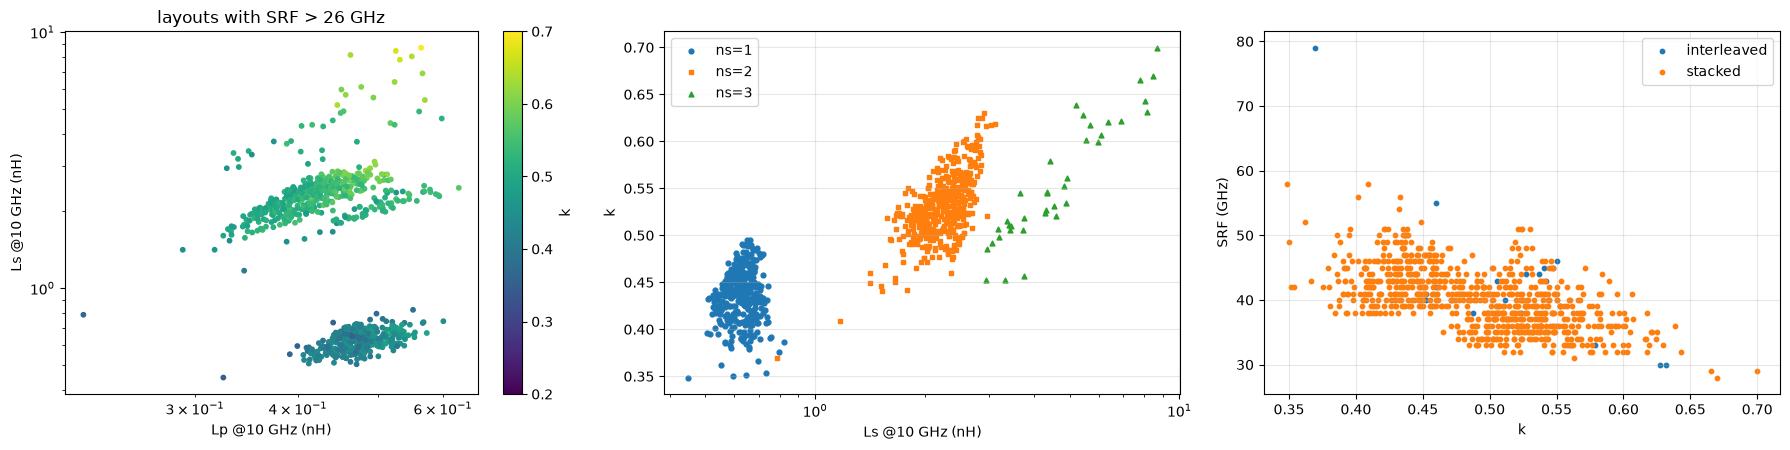

In [16]:
good = SRF > 26
fig_, ax = plt.subplots(1, 3, figsize=(18, 4.6))
sc = ax[0].scatter(Lp[good], Ls[good], c=k[good], s=10, cmap='viridis', vmin=0.2, vmax=0.7)
plt.colorbar(sc, ax=ax[0], label='k')
ax[0].set(xscale='log', yscale='log', xlabel='Lp @10 GHz (nH)', ylabel='Ls @10 GHz (nH)', title='layouts with SRF > 26 GHz')
for n_, mk in ((1, 'o'), (2, 's'), (3, '^')):
    sel = good & (ns == n_)
    ax[1].scatter(Ls[sel], k[sel], s=12, marker=mk, label=f'ns={n_}')
ax[1].set(xscale='log', xlabel='Ls @10 GHz (nH)', ylabel='k'); ax[1].legend(); ax[1].grid(alpha=.3)
ax[2].scatter(k[good & (sb == 0)], SRF[good & (sb == 0)], s=10, label='interleaved'); ax[2].scatter(k[good & (sb == 1)], SRF[good & (sb == 1)], s=10, label='stacked')
ax[2].set(xlabel='k', ylabel='SRF (GHz)'); ax[2].legend(); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

The data show three things that decide the design:

1. **Coupling.** Single-turn stacked layouts (`ns = 1`, `m = 1`, `sb = 1`) reach $k \approx 0.43$ to 0.5 with $L_p \approx 0.4$ to 0.55 nH and
   $L_s \approx 0.5$ to 0.65 nH, and their self-resonance stays at 40 to 56 GHz. A wider primary (`wp` $\ne$ `w`) does not raise $k$.
2. **More turns.** Two and three secondary turns give a higher coupling ($k$ = 0.53 to 0.70) but the secondary inductance grows to 2 to 9 nH with a low $Q_s$ and a low
   self-resonance, which is far from what the TIA needs.
3. **Orientation.** The primary and the secondary of a stacked layout differ in inductance (the leads and the ring positions are not symmetric), so which winding is used as the
   primary matters; Section 8 evaluates both orientations.

## 5. Neural Surrogates

The S-parameters of a transformer (4 ports) and of a spiral inductor (2 ports) are learned from the layout parameters.

* **Features.** 20 features describe a transformer (the 9 layout parameters, the winding length of each coil, length-to-width ratios, area, inner hole and the port-lead lengths). A spiral has its own 2-port feature set.
* **Targets.** The independent S-parameter entries by reciprocity (10 for the transformer, 3 for a spiral), real and imaginary parts, at 100 frequencies (1 to 100 GHz in 1 GHz steps).
* **Model.** An ensemble of 5 pre-LayerNorm residual MLPs (width 256, depth 4), trained with the L1 loss, and averaged. The spiral model uses the 1003 two-port EM simulations of the same generator
  (`spiral_gen.py`) that are part of the data set (`SPData/*.s2p`); no new EM is needed for L1 and Lb.

Training: `python surrogate.py --kind spiral` and `python surrogate.py --kind xfmr`. Both models report the test-set error of the S-parameters and of the figures of merit derived from them.

In [17]:
for kind in ('spiral', 'xfmr'):
    fn = f'models/{kind}_report.txt'
    print('=' * 20, kind); print(open(fn).read() if os.path.exists(fn) else 'not trained yet')

==================== spiral
[spiral] test samples 100 | |dS| mean 0.0020, max-per-sample median 0.0052 p90 0.0173
L10 err %: median 0.12 p90 0.55 max 1.36
Q10 err %: median 0.45 p90 1.82 max 5.70
Qmax err %: median 1.23 p90 8.55 max 29.45
SRF err %: median 0.00 p90 0.00 max 3.23
over frequency (mean of per-frequency medians): dS 0.0012, dL 0.1967, dQ 0.1934

==================== xfmr
[xfmr] test samples 53 | |dS| mean 0.0076, max-per-sample median 0.0234 p90 0.1155
Lp10 err %: median 0.30 p90 1.12 max 6.29
Ls10 err %: median 0.10 p90 1.16 max 27.91
n err %: median 0.10 p90 0.95 max 15.24
Qp10 err %: median 1.37 p90 7.97 max 101.25
Qs10 err %: median 0.83 p90 15.77 max 291.68
SRF err %: median 0.00 p90 2.61 max 48.78
k10 abs err: median 0.0010 p90 0.0075
over frequency (mean of per-frequency medians): dS 0.0009, dLp 0.3341, dLs 0.1000, dk 0.0050



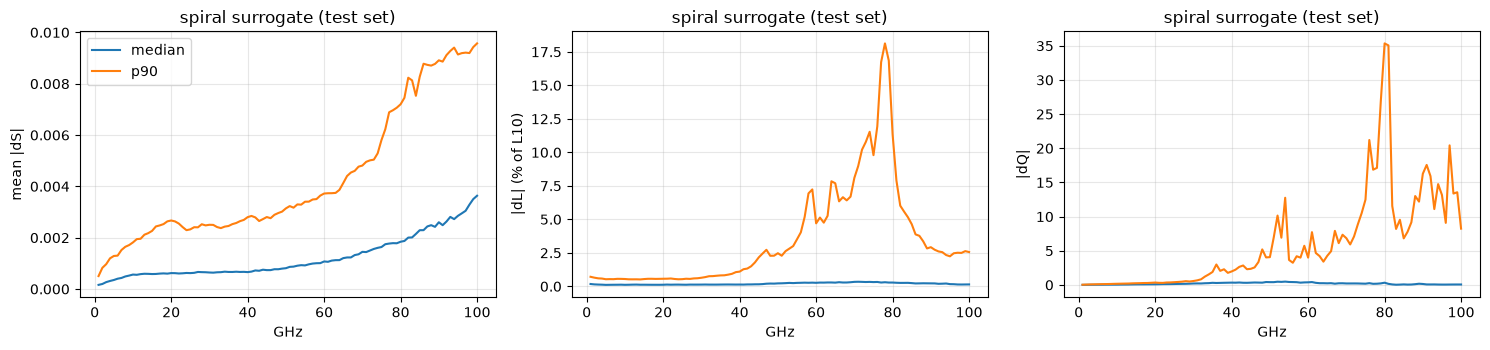

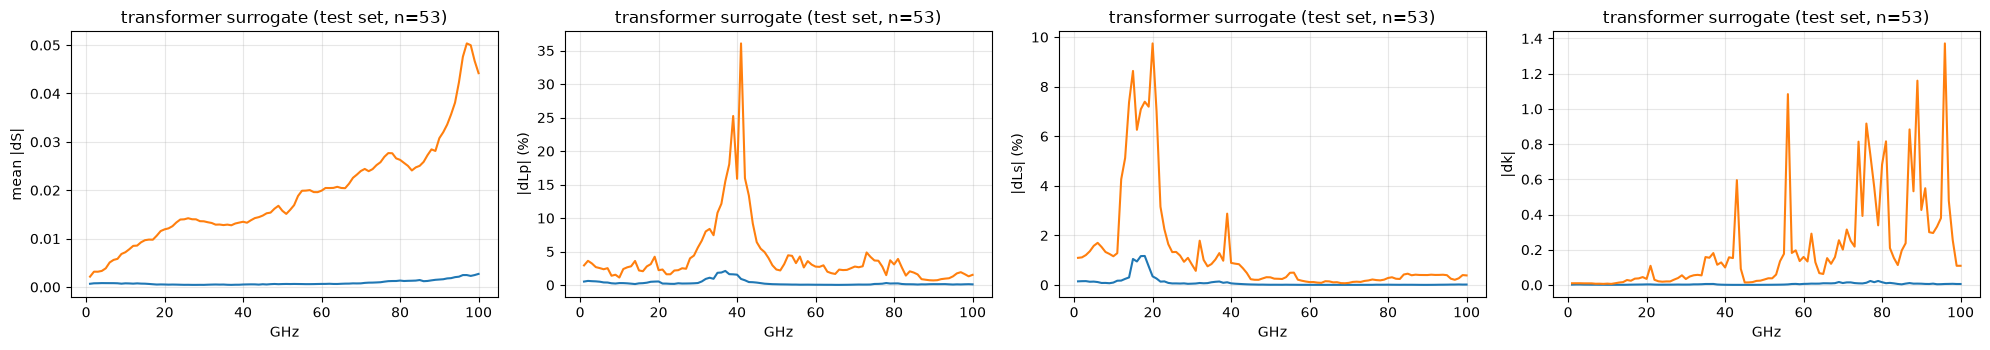

In [18]:
rs = json.load(open('models/spiral_report.json'))
fg = np.array(rs['freq_ghz'])
fig_, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, key, y in zip(ax, ('dS', 'dL', 'dQ'), ('mean |dS|', '|dL| (% of L10)', '|dQ|')):
    a.plot(fg, rs[f'{key}_f_median'], label='median'); a.plot(fg, rs[f'{key}_f_p90'], label='p90')
    a.set(xlabel='GHz', ylabel=y, title='spiral surrogate (test set)'); a.grid(alpha=.3)
ax[0].legend(); plt.tight_layout(); plt.show()
rx = json.load(open('models/xfmr_report.json'))
fig_, ax = plt.subplots(1, 4, figsize=(20, 3.6))
for a, key, y in zip(ax, ('dS', 'dLp', 'dLs', 'dk'), ('mean |dS|', '|dLp| (%)', '|dLs| (%)', '|dk|')):
    a.plot(fg, rx[f'{key}_f_median']); a.plot(fg, rx[f'{key}_f_p90'])
    a.set(xlabel='GHz', ylabel=y, title=f"transformer surrogate (test set, n={rx['n_test']})"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 6. SPICE Co-Simulation

### 6.1 Bias window of the npn

The npn13G2 has an emitter length of 0.9 $\mu$m per `Nx`. The simulation of $g_m/I_c$ and $f_T$ against the current density $J_c$ shows that $f_T$ stays above 85 % of its
peak up to the current density of the peak, so all transistors are kept between 1 and 3 mA/$\mu$m. This window is part of the cost function in Section 7.

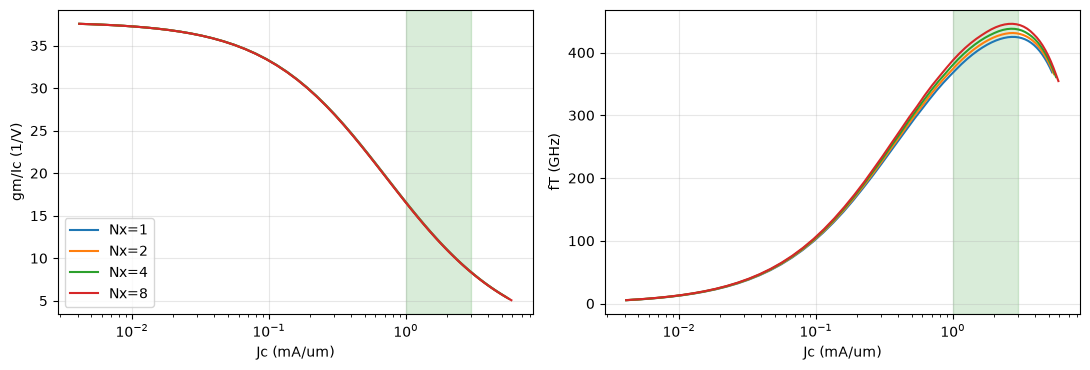

In [19]:
bs = json.load(open('results/bias_sweep.json'))
fig_, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for nx in (1, 2, 4, 8):
    r = sorted([b for b in bs if b['nx'] == nx and b['vce'] == 1.4], key=lambda b: b['jc'])
    ax[0].semilogx([b['jc'] for b in r], [b['gm_ic'] for b in r], label=f'Nx={nx}')
    ax[1].semilogx([b['jc'] for b in r], [b['ft'] / 1e9 for b in r])
for a, y in zip(ax, ('gm/Ic (1/V)', 'fT (GHz)')):
    a.axvspan(*T.JC_WIN, color='g', alpha=0.15); a.set(xlabel='Jc (mA/um)', ylabel=y); a.grid(alpha=.3)
ax[0].legend(); plt.tight_layout(); plt.show()

### 6.2 Netlist generation

`tia_sim.py` writes the complete testbench. An N-port S-matrix (surrogate or EM data) enters as an XSPICE `xfer` block per matrix entry. The
helper resistors are noiseless, and the DC path of the transformer is closed through a 1 mH inductor. In this way the same S4P file that was simulated with openEMS
is used by ngspice, including the loss of the windings and the capacitances, and the circuit noise comes out correctly.
The function `run` returns the differential transimpedance $Z_t(f)$, the band-average input noise and the power; `evaluate` extracts the bandwidth, peaking and group delay.

In [20]:
%%writefile tia_sim.py
# ngspice testbench of the transformer-based RGC TIA (Li & Palermo, JSSC 2013, Fig. 5) in SG13G2, VCC = 2.5 V.
# Stage 1 (transformer RGC input): Iin || Cpd -> L1 -> Q1 emitter; transformer primary Lp (P = e1, Pbar = r2) to R2;
#   secondary Ls (S = Q1 base, next to P; Sbar = Vb), S->Sbar flows opposite to P->Pbar, so k(P,Sbar) > 0 -> gm' = (1 + n k) gm.
#   R1 = Q1 collector load. EM 4-port order: 1 = P (e1), 2 = Pbar (r2), 3 = S (b1), 4 = Sbar (vb).
# Stage 2 (optional, '123'): Q2 common emitter with shunt feedback Rf (node A = c1 -> node B = b2), R4 load,
#   emitter R3 || C1 (MIM).
# Stage 3 (output buffer): single-ended -> differential pair Q3/Q4 (Nx = N3) with tail current IT; Q4 base = low-pass
#   replica of the Q3 base (offset free), loads VCC - R (50 ohm back termination) - Lb - collector, AC-coupled 50 ohm.
# Passive models: None | ('ideal', ...) | ('sp', f, S): 2-port spiral (L1, Lb) or 4-port transformer surrogate/EM data.
import os
import re
import shutil
import subprocess
import tempfile
import numpy as np

HERE = os.path.dirname(os.path.abspath(__file__))
NGSPICE = os.path.join(HERE, 'run_ngspice.sh')

VCC = 2.5
CPD = 220e-15                       # 150 fF photodiode + 70 fF pad (paper)
R_LOAD = 50.0                       # buffer back-termination resistor (paper)
RPPD_RSH = 260.0
CMIM_AREA = 1.5e-15                 # F/um^2 (cornerCAP.lib cap_carea)
F_REF = 1e9
LE = 0.9                            # emitter length of one npn13G2 emitter [um]
JC_WIN = (1.0, 3.0)                 # mA/um; bias_sweep.py: fT >= 85 % of its peak up to the peak-fT current density
BV_CE = 1.7                         # npn13G2 BVceo

# differential Zt (single-ended PD input, 2 x 50 ohm load), input-referred noise current, total power (paper Table)
SPEC = dict(zt_dbohm=59.0, bw_ghz=float(os.environ.get('TIA_BW_TARGET', 26.0)), peak_db=1.0, gd_pp_ps=10.0, noise_pa=21.3, power_mw=28.2)
MARGIN = dict(zt_dbohm=0.1, peak_db=0.1, gd_pp_ps=0.5, noise_pa=0.3, power_mw=0.3)   # optimisation target margins


def rppd_wl(r_ohm):
	"""rppd width/length for r_ohm: R ~ rsh*L/W + 2*rzspec/W (rzspec = 35e-6 ohm*m); wider for small R (L >= ~2 um)."""
	w = float(np.clip(2e-6 * 300.0 / r_ohm, 2e-6, 20e-6))
	return w, max((r_ohm - 2 * 35e-6 / w) * w / RPPD_RSH, 0.5e-6)


def res(name, a, b, r_ohm):
	w, l = rppd_wl(r_ohm)
	return f'X{name} {a} {b} 0 rppd w={w:.4e} l={l:.4e}'


def cmim(name, a, b, c):
	side = np.sqrt(max(c, 10e-15) / CMIM_AREA)
	return f'X{name} {a} {b} cap_cmim w={side:.3f}u l={side:.3f}u'


def sp_subckt(name, f, s):
	"""N-port S-parameter table -> ngspice XSPICE xfer subckt (pins: p1..pN ref); helper resistors are noiseless."""
	n = s.shape[1]
	ref = f'n{n + 1}'
	out = [f'.subckt {name} ' + ' '.join(f'n{i + 1}' for i in range(n)) + f' {ref}']
	for i in range(n):
		out += [f'R{i+1}N n{i+1} a{i+1}_0 -50 noisy=0', f'R{i+1}P a{i+1}_0 a{i+1}_1 100 noisy=0']
	for i in range(n):
		for j in range(n):
			nxt = ref if j == n - 1 else f'a{i+1}_{j+2}'
			k = i * n + j + 1
			out.append(f'A{i+1}_{j+1} %vd(a{j+1}_0 {ref}) %vd(a{i+1}_{j+1} {nxt}) xfer{k}')
			out.append(f'.model xfer{k} xfer R_I=true table=[')
			out += [f'+ {fk:.6e}Hz {s[q, i, j].real:.6e} {s[q, i, j].imag:.6e}' for q, fk in enumerate(f)]
			out.append('+ ]')
	out.append('.ends')
	return '\n'.join(out)


def sp_instance(tag, subckt, nodes, dc_pairs):
	"""xfer blocks have no DC path -> DC through 1 mH between the winding ends, xfer AC-coupled via 1 uF."""
	out = [f'Ldc{tag}{k} {a} {b} 1m' for k, (a, b) in enumerate(dc_pairs)]
	for k, nd in enumerate(nodes, 1):
		out += [f'Cb{tag}{k} {nd} lp{tag}{k} 1u', f'Rg{tag}{k} lp{tag}{k} 0 1G noisy=0']
	out.append(f'X{tag} ' + ' '.join(f'lp{tag}{k}' for k in range(1, len(nodes) + 1)) + f' 0 {subckt}')
	return out


def inductor(tag, a, b, model):
	"""Two-terminal coil a -> b (a = spiral port 1 = outer end)."""
	if model is None:
		return [f'V{tag} {a} {b} dc 0']
	if model[0] == 'ideal':
		return [f'L{tag} {a} {b} {model[1]:.4e}']
	return sp_instance(tag, f'sp{tag}', (a, b), [(a, b)])


def stage_nodes(stages):
	return 'b2' if '2' in stages else 'c1'


def netlist(p, xf=None, l1=None, lb=None, stages='13'):
	"""p: dict(N1, R1, R2, VB, N3, IT [, N2, R4, RF, R3, C1]); xf: None | ('ideal', Lp, Ls, k) | ('sp', f, S4)."""
	bin_ = stage_nodes(stages)
	lines = ['* SG13G2 transformer-RGC TIA', '.LIB cornerRES.lib res_typ', '.LIB cornerHBT.lib hbt_typ',
			 '.LIB cornerCAP.lib cap_typ', '']
	if xf is not None and xf[0] == 'sp':
		lines += [sp_subckt('spXF', xf[1], xf[2]), '']
	for tag, mdl in (('L1', l1), ('LBn', lb), ('LBp', lb)):
		if mdl is not None and mdl[0] == 'sp':
			lines += [sp_subckt(f'sp{tag}', mdl[1], mdl[2]), '']
	lines += [f'VCC vcc 0 dc {VCC}', f'VB vb 0 dc {p["VB"]:.4f}', 'Iin 0 pd dc 0 ac 1', f'Cpd pd 0 {CPD}']
	# stage 1: L1, Q1 (CB), transformer, R1, R2
	lines += inductor('L1', 'pd', 'e1', l1)
	lines += ['VQ1 c1 c1q dc 0', f'XQ1 c1q b1 e1 0 npn13G2 Nx={int(p["N1"])}',
			  res('R1', 'vcc', 'c1', p['R1']), res('R2', 'r2', '0', p['R2'])]
	if xf is None:
		lines += ['VXP e1 r2 dc 0', 'VXS vb b1 dc 0']
	elif xf[0] == 'ideal':
		lines += [f'LXP e1 r2 {xf[1]:.4e}', f'LXS vb b1 {xf[2]:.4e}', f'KX LXP LXS {xf[3]:.4f}']
	else:
		lines += sp_instance('XF', 'spXF', ('e1', 'r2', 'b1', 'vb'), [('e1', 'r2'), ('b1', 'vb')])
	# stage 2: shunt-feedback CE gain stage
	if '2' in stages:
		lines += ['VQ2 b2 b2q dc 0', f'XQ2 b2q c1 e2 0 npn13G2 Nx={int(p["N2"])}',
				  res('R4', 'vcc', 'b2', p['R4']), res('RF', 'c1', 'b2', p['RF']), res('R3', 'e2', '0', p['R3']),
				  cmim('C1', 'e2', '0', p['C1'])]
	# stage 3: differential output buffer (Q3 input side drives outn); Q4 base = buffered low-pass replica of the Q3 base
	lines += [f'Rlp {bin_} vlp 1k', 'Clp vlp 0 1u', 'Ebuf vbuf 0 vlp 0 1',
			  'VQ3 cn cnq dc 0', f'XQ3 cnq {bin_} t 0 npn13G2 Nx={int(p["N3"])}',
			  'VQ4 cp cpq dc 0', f'XQ4 cpq vbuf t 0 npn13G2 Nx={int(p["N3"])}',
			  f'IT t 0 dc {p["IT"]:.4e}',
			  res('RLn', 'vcc', 'rn', R_LOAD), res('RLp', 'vcc', 'rp', R_LOAD)]
	lines += inductor('LBn', 'rn', 'cn', lb) + inductor('LBp', 'rp', 'cp', lb)
	lines += ['Coutn cn outn 1n', 'RLDn outn 0 50', 'Coutp cp outp 1n', 'RLDp outp 0 50']
	nodes = ['pd', 'e1', 'b1', 'c1', 'r2', 't', 'cn', 'cp', 'vbuf'] + (['b2', 'e2'] if '2' in stages else [])
	currents = ['vcc', 'vb', 'vq1', 'vq3', 'vq4'] + (['vq2'] if '2' in stages else [])
	lines += ['', '.control', 'set filetype=ascii', 'op',
			  'print ' + ' '.join(f'v({n})' for n in nodes) + ' ' + ' '.join(f'i({c})' for c in currents),
			  'ac lin 199 1G 100G', 'wrdata tia_ac.txt v(outp,outn)',
			  'noise v(outp,outn) Iin lin 99 1G 50G', 'setplot noise1',
			  'wrdata tia_noise.txt inoise_spectrum', 'quit', '.endc', '.end']
	return '\n'.join(lines)


def run(p, xf=None, l1=None, lb=None, stages='13', keep=None):
	with tempfile.TemporaryDirectory(dir=os.environ.get('TIA_TMP', '/tmp')) as d:
		cir = os.path.join(d, 'tia.cir')
		shutil.copy(os.path.join(HERE, '.spiceinit'), d)
		txt = netlist(p, xf, l1, lb, stages)
		with open(cir, 'w') as fo:
			fo.write(txt)
		r = subprocess.run(['bash', NGSPICE, cir], cwd=d, capture_output=True, text=True, timeout=600)
		if keep:
			with open(keep, 'w') as fo:
				fo.write(txt + '\n\n* ---- log ----\n* ' + r.stdout.replace('\n', '\n* '))
		try:
			ac = np.loadtxt(os.path.join(d, 'tia_ac.txt'))
			nz = np.loadtxt(os.path.join(d, 'tia_noise.txt'))
		except (OSError, ValueError):
			return None
	op = {k: float(v) for k, v in re.findall(r'^((?:v|i)\(\w+\)) = ([-+0-9.eE]+)', r.stdout, re.M)}
	m = evaluate(ac[:, 0], ac[:, 1] + 1j * ac[:, 2], nz[:, 0], nz[:, 1], op)
	m['stages'] = stages
	return m


def evaluate(f, zt, fn, inoise, op):
	mag = np.abs(zt)
	z0 = np.interp(F_REF, f, mag)
	above = np.where((f > F_REF) & (mag < z0 / np.sqrt(2)))[0]
	if len(above):
		k = above[0]
		bw = np.interp(z0 / np.sqrt(2), [mag[k], mag[k - 1]], [f[k], f[k - 1]])
	else:
		bw = f[-1]
	peak = 20 * np.log10(mag[f <= bw].max() / z0)
	ph = np.unwrap(np.angle(zt))
	gd = -np.gradient(ph, 2 * np.pi * f)
	band = (f >= F_REF) & (f <= min(bw, SPEC['bw_ghz'] * 1e9))
	gd_pp = (gd[band].max() - gd[band].min()) if band.sum() > 2 else np.inf
	nb = (fn <= min(bw, fn[-1]))
	in_avg = np.sqrt(np.trapz(inoise[nb] ** 2, fn[nb]) / (fn[nb][-1] - fn[nb][0])) if nb.sum() > 2 else np.inf
	power = VCC * abs(op.get('i(vcc)', np.nan)) + abs(op.get('i(vb)', 0.0)) * op.get('v(b1)', 0.0)
	return dict(zt_dbohm=20 * np.log10(z0), bw_ghz=bw / 1e9, peak_db=peak, gd_pp_ps=gd_pp * 1e12,
				noise_pa=in_avg * 1e12, power_mw=power * 1e3, op=op, f=f, zt=zt, fn=fn, inoise=inoise)


def headroom(op):
	"""Bias violation [V]: no saturation (Vbc <= 0.2 V), Vce <= BVceo, tail current source headroom >= 0.5 V."""
	v = lambda n: op.get(f'v({n})', 0.0)
	two = 'v(b2)' in op
	bin_ = v('b2') if two else v('c1')
	viol = [v('b1') - v('c1') - 0.2, v('c1') - v('e1') - BV_CE,
			bin_ - v('cn') - 0.2, v('cn') - v('t') - BV_CE, v('cp') - v('t') - BV_CE, 0.5 - v('t')]
	if two:
		viol += [v('c1') - v('b2') - 0.2, v('b2') - v('e2') - BV_CE]
	return sum(max(0.0, x) for x in viol)


def jc_of(p, op):
	"""Collector current densities [mA/um] of Q1, (Q2), Q3, Q4 from the collector sense sources."""
	out = [abs(op.get('i(vq1)', 0.0)) * 1e3 / (p['N1'] * LE)]
	if 'i(vq2)' in op:
		out.append(abs(op['i(vq2)']) * 1e3 / (p['N2'] * LE))
	out += [abs(op.get(f'i({q})', 0.0)) * 1e3 / (p['N3'] * LE) for q in ('vq3', 'vq4')]
	return [max(j, 1e-6) for j in out]


def bias_penalty(p, op):
	"""Log-distance of the current densities outside JC_WIN (0 inside)."""
	return sum(max(0.0, np.log(JC_WIN[0] / j), np.log(j / JC_WIN[1])) for j in jc_of(p, op))


def violations(m):
	"""Spec violations with optimisation margins (all >= 0, 0 = met)."""
	t = {k: SPEC[k] + (MARGIN.get(k, 0) if k == 'zt_dbohm' else -MARGIN.get(k, 0)) for k in SPEC}
	return dict(zt=max(0, t['zt_dbohm'] - m['zt_dbohm']), peak=max(0, m['peak_db'] - t['peak_db']),
				gd=max(0, m['gd_pp_ps'] - t['gd_pp_ps']), noise=max(0, m['noise_pa'] - t['noise_pa']),
				power=max(0, m['power_mw'] - t['power_mw']), bw=max(0, SPEC['bw_ghz'] - m['bw_ghz']))


def cost(m):
	"""Maximize bandwidth subject to the spec constraints (lower is better)."""
	if m is None or not np.isfinite(m['gd_pp_ps']):
		return 1e3
	v = violations(m)
	pen = (20 * v['zt'] + 30 * v['peak'] + 3 * v['gd'] + 2 * v['noise'] + 5 * v['power'] + 50 * headroom(m['op']))
	return -m['bw_ghz'] - 0.5 * (m['zt_dbohm'] - SPEC['zt_dbohm']) + pen


def meets(m, tol=0.0):
	"""True if every spec (incl. BW) is met without the optimisation margins."""
	if m is None:
		return False
	return (m['zt_dbohm'] >= SPEC['zt_dbohm'] - tol and m['bw_ghz'] >= SPEC['bw_ghz'] - tol
			and m['peak_db'] <= SPEC['peak_db'] + tol and m['gd_pp_ps'] <= SPEC['gd_pp_ps'] + tol
			and m['noise_pa'] <= SPEC['noise_pa'] + tol and m['power_mw'] <= SPEC['power_mw'] + tol
			and headroom(m['op']) < 1e-3)


def summary(m):
	return ' '.join(f'{k}={m[k]:.2f}' for k in SPEC) if m else 'FAILED'


if __name__ == '__main__':
	# quick self-test: paper-like stage 1 + 3 and 1 + 2 + 3 with ideal passives
	p = dict(N1=2, R1=300, R2=500, VB=1.3, N3=4, IT=8e-3, N2=2, R4=300, RF=800, R3=200, C1=500e-15)
	for st in ('13', '123'):
		for xf in (None, ('ideal', 0.28e-9, 1.09e-9, 0.7)):
			m = run(p, xf, ('ideal', 0.3e-9), ('ideal', 0.4e-9), st)
			print(st, 'xfmr' if xf else 'none ', summary(m), 'headroom', round(headroom(m['op']), 3) if m else '-',
				  'Jc', np.round(jc_of(p, m['op']), 2) if m else '-')

Overwriting tia_sim.py


In [21]:
import importlib, tia_sim as T
importlib.reload(T)
p = json.load(open('results/ideal_s123_ns1reg_best.json'))['params']
net = T.netlist(p, ('ideal', p['Lp'], p['Ls'], p['k']), ('ideal', p['L1']), ('ideal', p['LB']), '123')
print('\n'.join(net.split('\n')[:42]))

* SG13G2 transformer-RGC TIA
.LIB cornerRES.lib res_typ
.LIB cornerHBT.lib hbt_typ
.LIB cornerCAP.lib cap_typ

VCC vcc 0 dc 2.5
VB vb 0 dc 0.9690
Iin 0 pd dc 0 ac 1
Cpd pd 0 2.2e-13
LL1 pd e1 6.8754e-11
VQ1 c1 c1q dc 0
XQ1 c1q b1 e1 0 npn13G2 Nx=3
XR1 vcc c1 0 rppd w=2.0000e-06 l=6.5872e-06
XR2 r2 0 0 rppd w=1.0864e-05 l=2.0385e-06
LXP e1 r2 4.9252e-10
LXS vb b1 6.3610e-10
KX LXP LXS 0.4593
VQ2 b2 b2q dc 0
XQ2 b2q c1 e2 0 npn13G2 Nx=3
XR4 vcc b2 0 rppd w=2.3253e-06 l=2.0385e-06
XRF c1 b2 0 rppd w=2.0000e-06 l=2.0814e-05
XR3 e2 0 0 rppd w=2.0000e-05 l=1.2778e-06
XC1 e2 0 cap_cmim w=10.255u l=10.255u
Rlp b2 vlp 1k
Clp vlp 0 1u
Ebuf vbuf 0 vlp 0 1
VQ3 cn cnq dc 0
XQ3 cnq b2 t 0 npn13G2 Nx=3
VQ4 cp cpq dc 0
XQ4 cpq vbuf t 0 npn13G2 Nx=3
IT t 0 dc 5.3636e-03
XRLn vcc rn 0 rppd w=1.2000e-05 l=2.0385e-06
XRLp vcc rp 0 rppd w=1.2000e-05 l=2.0385e-06
LLBn rn cn 2.1235e-10
LLBp rp cp 2.1235e-10
Coutn cn outn 1n
RLDn outn 0 50
Coutp cp outp 1n
RLDp outp 0 50

.control
set filetype=ascii


## 7. Co-Design with CMA-ES

The optimiser (optuna with the CMA-ES sampler, 12 parallel ngspice runs) selects the transistor sizes `N1`, `N2`, `N3`, the resistors, `Vb`, the tail current and the
passives. The cost function is the negative bandwidth plus penalties:

* **Specification penalties** for the transimpedance, peaking, group delay, noise and power that are above their limits (with a small safety margin),
* **bias penalties** for transistors outside the current-density window, for saturation of Q1 to Q4 and for a tail-source headroom below 0.5 V.

Four modes use the same cost function:

| Mode | Stage-1 transformer | L1 and Lb |
|:--|:--|:--|
| `noX` | none (the base is tied to Vb) | ideal |
| `ideal` | ideal coupled inductors; Lp, Ls, k are free variables inside bounds (`--xbounds`) | ideal |
| `em` | S-parameters of the surrogate; the layout parameters are the variables | surrogates |
| `em_noX` | none | surrogates |

`TIA_BW_TARGET` sets the bandwidth for which the `meets` flag is evaluated and over which the group delay is measured. With `--swap` the P and S
roles of the transformer are exchanged.

In [22]:
%%writefile codesign.py
# Active/passive co-design of the transformer-RGC TIA (SG13G2) with optuna CMA-ES + ngspice.
# Modes:  noX    - plain common-base input (no transformer), ideal L1 / Lb
#         ideal  - ideal coupled inductors (Lp, Ls, k) + ideal L1 / Lb
#         em     - transformer [w, s, ns, m, D] and spirals L1, Lb [w, s, n, Dx, Dy] from the EM-trained surrogates
#         em_noX - no transformer, spirals from the surrogate (EM baseline for the with/without comparison)
# Stages: 13 (RGC input + output buffer) or 123 (+ shunt-feedback gain stage).
# Usage: python codesign.py --mode ideal --stages 13 [--trials 3000] [--jobs 12] [--tag run1]
import argparse
import json
import os
import time
from multiprocessing import Pool
import numpy as np
import optuna
import tia_sim as T
import xfmr_gen
import spiral_gen

HERE = os.path.dirname(os.path.abspath(__file__))
RES = f'{HERE}/results'

ACTIVE1 = dict(N1=('int', 1, 10), R1=('log', 50.0, 2000.0), R2=('log', 20.0, 2000.0), VB=('float', 0.9, 1.9))
ACTIVE2 = dict(N2=('int', 1, 10), R4=('log', 50.0, 1500.0), RF=('log', 100.0, 3000.0), R3=('log', 10.0, 1500.0),
			   C1=('log', 50e-15, 3e-12))
ACTIVE3 = dict(N3=('int', 1, 12), IT=('log', 2e-3, 16e-3))
IDEAL_X = dict(Lp=('log', 0.05e-9, 1.5e-9), Ls=('log', 0.1e-9, 4e-9), k=('float', 0.3, 0.85))
IDEAL_L = dict(L1=('log', 0.05e-9, 2e-9), LB=('log', 0.05e-9, 1.5e-9))
XKEYS = xfmr_gen.KEYS
SKEYS = ('w', 's', 'n', 'Dx', 'Dy')
GEOM_X = {f'x_{k}': v for k, v in zip(XKEYS, [('int', xfmr_gen.W_MIN, xfmr_gen.W_MAX), ('int', 2, 6), ('int', 1, 3), ('int', 1, 2),
											  ('int', xfmr_gen.D_MIN, xfmr_gen.D_MAX), ('int', 0, 1), ('int', 0, 1),
											  ('int', xfmr_gen.U_MIN, xfmr_gen.U_MAX), ('int', xfmr_gen.W_MIN, xfmr_gen.W_MAX)])}
GEOM_S = [('int', 3, 10), ('int', 2, 8), ('int', 1, 3), ('int', 20, spiral_gen.D_MAX), ('int', 20, spiral_gen.D_MAX)]
GEOM_L1 = {f'l1_{k}': v for k, v in zip(SKEYS, GEOM_S)}
GEOM_LB = {f'lb_{k}': v for k, v in zip(SKEYS, GEOM_S)}
AREA_W = 0.01 / 1000          # cost per um^2 of passive bounding boxes (tie-breaker: 0.01 per 1000 um^2)
BIAS_W = 10.0                 # cost per unit ln-distance of a transistor Jc outside tia_sim.JC_WIN
RATIO = []                    # allowed Ls/Lp window of the ideal transformer (set by --ratio)
SWAP = []                     # [True]: layout winding S is used as primary and P as secondary (ports 1<->3, 2<->4)


def swap_ports(s):
	if not SWAP or s is None:
		return s
	return s[..., [2, 3, 0, 1], :][..., [2, 3, 0, 1]]


def space_of(mode, stages):
	sp = dict(ACTIVE1)
	if '2' in stages:
		sp.update(ACTIVE2)
	sp.update(ACTIVE3)
	if mode in ('noX', 'ideal'):
		sp.update(IDEAL_L)
	if mode == 'ideal':
		sp.update(IDEAL_X)
	if mode in ('em', 'em_noX'):
		sp.update(GEOM_L1)
		sp.update(GEOM_LB)
	if mode == 'em':
		sp.update(GEOM_X)
	return sp


def suggest(trial, space):
	out = {}
	for k, (t, lo, hi) in space.items():
		out[k] = trial.suggest_int(k, lo, hi) if t == 'int' else trial.suggest_float(k, lo, hi, log=(t == 'log'))
	return out


def xgeo(p):
	return [p['x_' + k] for k in XKEYS]


def sgeo(p, tag):
	return [p[f'{tag}_{k}'] for k in SKEYS]


def spiral_area(g):
	w, s, n, Dx, Dy = g
	return (Dx + 2 * (w + s)) * (Dy + w)


def passive_area(p, mode):
	if mode not in ('em', 'em_noX'):
		return 0.0
	a = spiral_area(sgeo(p, 'l1')) + 2 * spiral_area(sgeo(p, 'lb'))
	return a + (xfmr_gen.xfmr_area(xgeo(p)) if mode == 'em' else 0.0)


def valid(p, mode):
	if mode == 'ideal' and RATIO and not RATIO[0] <= p['Ls'] / p['Lp'] <= RATIO[1]:
		return False
	if mode not in ('em', 'em_noX'):
		return True
	ok = all(spiral_gen.is_valid(*sgeo(p, t)) for t in ('l1', 'lb'))
	return ok and (mode != 'em' or xfmr_gen.is_valid(*xgeo(p)))


def models_of(p, mode, sx=None, s1=None, sb=None, freq=None):
	"""(xf, l1, lb) passive models for tia_sim.run."""
	if mode in ('noX', 'ideal'):
		xf = ('ideal', p['Lp'], p['Ls'], p['k']) if mode == 'ideal' else None
		return xf, ('ideal', p['L1']), ('ideal', p['LB'])
	return (('sp', freq, swap_ports(sx)) if mode == 'em' else None), ('sp', freq, s1), ('sp', freq, sb)


def worker(job):
	p, xf, l1, lb, area, stages = job
	try:
		m = T.run(p, xf, l1, lb, stages)
	except Exception:
		m = None
	c = T.cost(m) + AREA_W * area
	if m is not None:
		c += BIAS_W * T.bias_penalty(p, m['op'])
		m['jc'] = T.jc_of(p, m['op'])
		m = {k: v for k, v in m.items() if k not in ('f', 'zt', 'fn', 'inoise')}
	return c, m


def predict_passives(params, ok, mode, sur_x, sur_s):
	"""Batched surrogate predictions for the valid candidates -> {i: (sx, s1, sb)}."""
	if not ok:
		return {}
	s1 = sur_s.predict(np.array([sgeo(params[i], 'l1') for i in ok]))
	sb = sur_s.predict(np.array([sgeo(params[i], 'lb') for i in ok]))
	sx = sur_x.predict(np.array([xgeo(params[i]) for i in ok])) if mode == 'em' else [None] * len(ok)
	return {i: (sx[k], s1[k], sb[k]) for k, i in enumerate(ok)}


def optimise(mode, stages, trials, jobs, seed, sur_x=None, sur_s=None):
	space = space_of(mode, stages)
	sampler = optuna.samplers.CmaEsSampler(seed=seed, n_startup_trials=4 * jobs, with_margin=True,
										   warn_independent_sampling=False)
	study = optuna.create_study(direction='minimize', sampler=sampler)
	log = []
	t0 = time.time()
	em = mode in ('em', 'em_noX')
	with Pool(jobs) as pool:
		done = 0
		while done < trials:
			batch = [study.ask() for _ in range(min(jobs, trials - done))]
			params = [suggest(t, space) for t in batch]
			if mode in ('em', 'em_noX'):
				for p in params:
					for t in ('l1', 'lb'):
						w, s, n, Dx, Dy = sgeo(p, t)
						dmin = (2 * n + 1) * (w + s)
						p[f'{t}_Dx'], p[f'{t}_Dy'] = max(Dx, dmin), max(Dy, dmin)
			if mode == 'em':
				for p in params:
					p.update(zip(['x_' + k for k in XKEYS], xfmr_gen.repair(xgeo(p))))
			ok = [i for i, p in enumerate(params) if valid(p, mode)]
			pred = predict_passives(params, ok, mode, sur_x, sur_s) if em else {}
			jobs_in = []
			for i, p in enumerate(params):
				if i not in ok:
					jobs_in.append(None)
					continue
				mdl = models_of(p, mode, *pred[i], sur_s.freq) if em else models_of(p, mode)
				jobs_in.append((p, *mdl, passive_area(p, mode), stages))
			res = pool.map(worker, [j for j in jobs_in if j is not None])
			it = iter(res)
			for t, p, j in zip(batch, params, jobs_in):
				c, m = next(it) if j is not None else (1e3, None)
				study.tell(t, c)
				log.append(dict(cost=c, params=p, metrics=m))
			done += len(batch)
			if done % (jobs * 50) == 0 or done >= trials:
				b = study.best_trial
				print(f'[{mode}/{stages}] {done}/{trials} {time.time() - t0:.0f}s best cost {b.value:.3f} '
					  f'{T.summary(log[b.number]["metrics"])}', flush=True)
	return study, log


def passive_figures(p, mode, sur_x, sur_s):
	from surrogate import xfmr_figures, spiral_figures
	out = {}
	if mode == 'em':
		out['xfmr'] = {k: float(v) for k, v in xfmr_figures(sur_x.freq, swap_ports(sur_x.predict([xgeo(p)])[0])).items()}
	for t in ('l1', 'lb'):
		out[t] = {k: float(v) for k, v in spiral_figures(sur_s.freq, sur_s.predict([sgeo(p, t)])[0]).items()}
	return out


def geom_key(p, mode):
	g = sgeo(p, 'l1') + sgeo(p, 'lb')
	return tuple(g + (xgeo(p) if mode == 'em' else []))


def main():
	ap = argparse.ArgumentParser()
	ap.add_argument('--mode', choices=['noX', 'ideal', 'em', 'em_noX'], required=True)
	ap.add_argument('--stages', choices=['13', '123'], default='13')
	ap.add_argument('--trials', type=int, default=3000)
	ap.add_argument('--jobs', type=int, default=12)
	ap.add_argument('--seed', type=int, default=0)
	ap.add_argument('--xmodel', default=f'{HERE}/models/xfmr.pt')
	ap.add_argument('--smodel', default=f'{HERE}/models/spiral.pt')
	ap.add_argument('--tag', default='run1')
	ap.add_argument('--xbounds', help='ideal mode: Lp_lo,Lp_hi,Ls_lo,Ls_hi [nH],k_lo,k_hi (realisable transformer)')
	ap.add_argument('--ratio', help='ideal mode: allowed Ls/Lp window lo,hi (planar layouts cannot realise every turns ratio)')
	ap.add_argument('--swap', action='store_true', help='em mode: use layout winding S as primary and P as secondary')
	a = ap.parse_args()
	if a.swap:
		SWAP.append(True)
	if a.ratio:
		RATIO[:] = [float(v) for v in a.ratio.split(',')]
	if a.xbounds:
		lo1, hi1, lo2, hi2, klo, khi = (float(v) for v in a.xbounds.split(','))
		IDEAL_X.update(Lp=('log', lo1 * 1e-9, hi1 * 1e-9), Ls=('log', lo2 * 1e-9, hi2 * 1e-9), k=('float', klo, khi))
	os.makedirs(RES, exist_ok=True)
	os.environ.setdefault('TIA_TMP', '/tmp')
	optuna.logging.set_verbosity(optuna.logging.WARNING)

	sur_x = sur_s = None
	if a.mode in ('em', 'em_noX'):
		from surrogate import Surrogate
		sur_s = Surrogate(a.smodel)
		if a.mode == 'em':
			sur_x = Surrogate(a.xmodel)
	study, log = optimise(a.mode, a.stages, a.trials, a.jobs, a.seed, sur_x, sur_s)

	ranked = sorted(log, key=lambda r: r['cost'])
	best = dict(ranked[0])
	best['mode'], best['stages'] = a.mode, a.stages
	if a.mode in ('em', 'em_noX'):
		best['passives'] = passive_figures(best['params'], a.mode, sur_x, sur_s)
		best['area_um2'] = passive_area(best['params'], a.mode)
		# distinct geometries among the top designs, for EM verification
		top, seen = [], set()
		for r in ranked:
			g = geom_key(r['params'], a.mode)
			if g not in seen and r['metrics'] is not None:
				seen.add(g)
				top.append(r)
			if len(top) == 5:
				break
		best['top5'] = top
	name = f'{RES}/{a.mode}_s{a.stages}_{a.tag}'
	with open(name + '_best.json', 'w') as fo:
		json.dump(best, fo, indent=1, default=float)
	with open(name + '_trials.json', 'w') as fo:
		json.dump(log, fo, default=float)
	print('BEST', a.mode, a.stages, json.dumps(best['params'], default=float))
	print('     ', T.summary(best['metrics']), 'meets spec:', T.meets(best['metrics']))
	if 'passives' in best:
		print('      passives', best['passives'], 'area', best['area_um2'])


if __name__ == '__main__':
	main()

Overwriting codesign.py


Commands (each run is one result file `results/{mode}_s{stages}_{tag}_best.json` plus the trial history):

```bash
export TIA_BW_TARGET=26
python codesign.py --mode noX   --stages 123 --tag cmp26 --trials 3000
python codesign.py --mode ideal --stages 123 --tag cmp26 --trials 3000 --xbounds 0.15,0.9,0.2,5,0.0,0.72
python codesign.py --mode ideal --stages 123 --tag ns1reg --xbounds <bounds of the realised ns=1 region>
python codesign.py --mode em    --stages 123 --tag em [--swap]     # surrogate in the loop
```

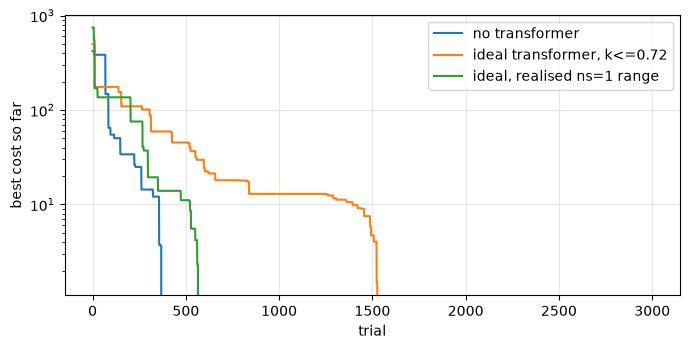

In [23]:
import codesign as CD
fig_, ax = plt.subplots(figsize=(7, 3.6))
for label, fn in (('no transformer', 'noX_s123_cmp26'), ('ideal transformer, k<=0.72', 'ideal_s123_cmp26'), ('ideal, realised ns=1 range', 'ideal_s123_ns1reg')):
    f = f'results/{fn}_trials.json'
    if not os.path.exists(f): continue
    cost = [t['cost'] for t in json.load(open(f))]
    ax.semilogy(np.minimum.accumulate(cost), label=label)
ax.set(xlabel='trial', ylabel='best cost so far'); ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

## 8. Transformer Versus No Transformer

### 8.1 Ideal elements

All rows use the three-stage amplifier and the same trial budget. In the "ideal" rows, the transformer is a pair of ideal coupled inductors and L1 and Lb are ideal.

* **no transformer**: the plain common-base input stage.
* **ideal, $k \le 0.72$**: $L_p$, $L_s$ and $k$ are free inside the layout-realisable ranges $L_p \in$ [0.15, 0.9] nH, $L_s \in$ [0.2, 5] nH.
* **ideal, realised ns=1 range**: the same optimisation restricted to the (Lp, Ls, k) that the EM data of Section 4 show for single-turn layouts, both in the original and in the port-swapped orientation.

design                               zt_dbohm     bw_ghz    peak_db   gd_pp_ps   noise_pa   power_mw   meets
no transformer                          62.54      20.50       0.00       2.62      20.93      27.84   False
ideal, k<=0.72                          60.79      37.97       0.86       5.89      20.88      25.86   True
ideal, EM-realised ns=1 range           60.46      35.84       0.35       6.80      19.54      26.12   True
ideal, ns=1 range, P/S swapped          61.85      40.78       0.62       3.60      21.92      27.48   False
spec                                    59.00      26.00       1.00      10.00      21.30      28.20
ideal, k<=0.72: Lp=0.471 nH  Ls=0.343 nH  k=0.60
ideal, EM-realised ns=1 range: Lp=0.493 nH  Ls=0.636 nH  k=0.46
ideal, ns=1 range, P/S swapped: Lp=0.565 nH  Ls=0.468 nH  k=0.50


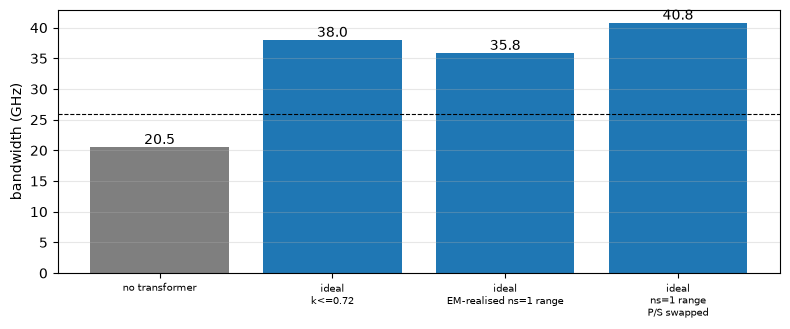

In [24]:
rows = []
for label, fn in (('no transformer', 'noX_s123_cmp26'), ('ideal, k<=0.72', 'ideal_s123_cmp26'),
                  ('ideal, EM-realised ns=1 range', 'ideal_s123_ns1reg'), ('ideal, ns=1 range, P/S swapped', 'ideal_s123_ns1regsw'),
                  ('EM surrogate', 'em_s123_em')):
    f = f'results/{fn}_best.json'
    if os.path.exists(f):
        b = json.load(open(f)); rows.append((label, b['metrics'], b['params']))
print(f"{'design':34s}" + ''.join(f'{k:>11s}' for k in T.SPEC) + '   meets')
for label, mm, pp in rows:
    print(f'{label:34s}' + ''.join(f'{mm[k]:11.2f}' for k in T.SPEC) + f'   {T.meets(mm)}')
print(f"{'spec':34s}" + ''.join(f'{T.SPEC[k]:11.2f}' for k in T.SPEC))
for label, mm, pp in rows:
    if 'Lp' in pp: print(f'{label}: Lp={pp["Lp"]*1e9:.3f} nH  Ls={pp["Ls"]*1e9:.3f} nH  k={pp["k"]:.2f}')
plt.figure(figsize=(8, 3.4))
bars = plt.bar(range(len(rows)), [r[1]['bw_ghz'] for r in rows], color=['C7'] + ['C0'] * (len(rows) - 1))
plt.bar_label(bars, fmt='%.1f')
plt.xticks(range(len(rows)), [r[0].replace(', ', '\n') for r in rows], fontsize=7)
plt.axhline(26, ls='--', c='k', lw=.8); plt.ylabel('bandwidth (GHz)'); plt.grid(alpha=.3, axis='y'); plt.tight_layout(); plt.show()

### 8.2 Real EM transformers in the TIA

An ideal coupled-inductor pair can have any $k$. The question that matters for a layout is what the **simulated** transformers give.
`layout_bw.py` therefore takes each simulated S4P file with $L_p$, $L_s \in$ [0.3, 1.2] nH and an SRF above 26 GHz, places it in the TIA together with the bias point and the
passives of the matching ideal optimisation (`ns1reg` for the original port order, `ns1regsw` for the port-swapped one), and simulates the TIA in ngspice. The active-device values are not
re-optimised for each layout, which means that the result is a conservative lower bound: a layout whose inductances differ from the ideal ones will have a small
peaking or noise violation that a re-optimisation of the bias would remove. The layouts that meet all specifications without any re-optimisation are listed first.

In [25]:
%%writefile layout_bw.py
# BW of the real EM transformers (S4P) in the stage-1+2+3 TIA, for both winding orientations.
# Stage 1: fixed active/L1/LB values of the matching ideal run (ns1reg / ns1regsw) for all layouts with Lp, Ls in 0.3-1.2 nH.
# Stage 2: CMA-ES re-optimisation of the top layouts of each orientation. Writes results/layout_bw.json.
import json
import os
import sys
from multiprocessing import Pool
import numpy as np
import optuna
import codesign as C
import surrogate as S
import tia_sim as T

os.environ.setdefault('TIA_TMP', '/tmp')
optuna.logging.set_verbosity(optuna.logging.WARNING)
JOBS, N_TOP, N_OPT = 12, 6, 360
REF = {False: 'ns1reg', True: 'ns1regsw'}


def swap(s):
	return s[..., [2, 3, 0, 1], :][..., [2, 3, 0, 1]]


def job_of(p, s):
	return (p, ('sp', S.FREQ, s), ('ideal', p['L1']), ('ideal', p['LB']), '123')


def short(m):
	if m is None:
		return None
	return dict(bw=m['bw_ghz'], zt=m['zt_dbohm'], peak=m['peak_db'], gd=m['gd_pp_ps'], noise=m['noise_pa'], power=m['power_mw'], meets=bool(T.meets(m)))


def worker1(j):
	try:
		m = T.run(*j)
	except Exception:
		m = None
	return short(m)


def optimise(p0, s, seed=0):
	space = C.space_of('noX', '123')
	space = {k: v for k, v in space.items()}
	sampler = optuna.samplers.CmaEsSampler(seed=seed, n_startup_trials=0, with_margin=True, warn_independent_sampling=False,
										   x0={k: p0[k] for k in space})
	study = optuna.create_study(direction='minimize', sampler=sampler)
	study.enqueue_trial({k: p0[k] for k in space})
	best = (1e9, None, None)
	with Pool(JOBS) as pool:
		done = 0
		while done < N_OPT:
			batch = [study.ask() for _ in range(JOBS)]
			ps = [C.suggest(t, space) for t in batch]
			res = pool.map(C.worker, [(p, ('sp', S.FREQ, s), ('ideal', p['L1']), ('ideal', p['LB']), 0.0, '123') for p in ps])
			for t, p, (c, m) in zip(batch, ps, res):
				study.tell(t, c)
				if c < best[0]:
					best = (c, p, m)
			done += JOBS
	return best


if __name__ == '__main__':
	geo, s_all, idx = S.KINDS['xfmr'].load_dataset()
	figs = []
	for sp in s_all:
		f = S.xfmr_figures(S.FREQ, sp)
		figs.append((float(f['Lp10']) * 1e9, float(f['Ls10']) * 1e9, float(f['k10']), float(f['SRF']) / 1e9))
	figs = np.array(figs)
	cand = [j for j in range(len(idx)) if 0.3 <= figs[j, 0] <= 1.2 and 0.3 <= figs[j, 1] <= 1.2 and figs[j, 3] > 26]
	print('candidates', len(cand), flush=True)
	out = dict(stage1=[], stage2=[])
	ref = {}
	for sw, tag in REF.items():
		ref[sw] = json.load(open(f'{C.RES}/ideal_s123_{tag}_best.json'))['params']
	with Pool(JOBS) as pool:
		for sw in (False, True):
			jobs = [job_of(ref[sw], swap(s_all[j]) if sw else s_all[j]) for j in cand]
			res = pool.map(worker1, jobs)
			for j, r in zip(cand, res):
				out['stage1'].append(dict(idx=int(idx[j]), swap=sw, geo=[int(v) for v in geo[j]], fig=[float(v) for v in figs[j]], m=r))
			print('stage1 swap', sw, 'done', flush=True)
	json.dump(out, open(f'{C.RES}/layout_bw.json', 'w'), indent=0)
	for sw in (False, True):
		rows = [r for r in out['stage1'] if r['swap'] == sw and r['m']]
		rows.sort(key=lambda r: -r['m']['bw'])
		print('swap', sw, 'top fixed-active BW:', [(r['idx'], round(r['m']['bw'], 1)) for r in rows[:10]], flush=True)
		for r in rows[:N_TOP]:
			j = list(idx).index(r['idx'])
			c, p, m = optimise(ref[sw], swap(s_all[j]) if sw else s_all[j])
			mm = short(m)
			out['stage2'].append(dict(idx=r['idx'], swap=sw, geo=r['geo'], fig=r['fig'], m=mm, params=p))
			print('  opt idx', r['idx'], 'swap', sw, mm, flush=True)
			json.dump(out, open(f'{C.RES}/layout_bw.json', 'w'), indent=0, default=float)
	print('DONE')

Overwriting layout_bw.py


In [26]:
lb = json.load(open('results/layout_bw.json'))
s1 = [r for r in lb['stage1'] if r['m']]
print(len(s1), 'layout/orientation combinations simulated with the fixed active circuit')
for sw in (False, True):
    rr = sorted([r for r in s1 if r['swap'] == sw], key=lambda r: -r['m']['bw'])
    nm = sum(r['m']['meets'] for r in rr)
    print(f"\norientation {'swapped' if sw else 'original'}: {len(rr)} layouts, {nm} meet all specifications, "
          f"{sum(r['m']['bw'] > 20.5 for r in rr)} have BW > 20.5 GHz, {sum(r['m']['bw'] > 20.5 and r['m']['peak'] <= 1 for r in rr)} of them with peaking <= 1 dB")
    print(f"{'idx':>6s} {'geometry':32s}{'Lp':>6s}{'Ls':>6s}{'k':>6s}{'SRF':>5s}{'BW':>7s}{'Zt':>7s}{'peak':>6s}{'GD':>6s}{'noise':>7s}{'P':>6s}  meets")
    for r in rr[:8]:
        g, f_, mm = r['geo'], r['fig'], r['m']
        print(f"{r['idx']:6d} {str(g):32s}{f_[0]:6.2f}{f_[1]:6.2f}{f_[2]:6.2f}{f_[3]:5.0f}{mm['bw']:7.1f}{mm['zt']:7.1f}{mm['peak']:6.1f}{mm['gd']:6.1f}{mm['noise']:7.1f}{mm['power']:6.1f}  {mm['meets']}")

650 layout/orientation combinations simulated with the fixed active circuit

orientation original: 325 layouts, 2 meet all specifications, 324 have BW > 20.5 GHz, 2 of them with peaking <= 1 dB
   idx geometry                            Lp    Ls     k  SRF     BW     Zt  peak    GD  noise     P  meets
  2844 [5, 2, 1, 1, 147, 1, 1, 30, 5]    0.41  0.51  0.43   54   36.6   60.6   2.2   8.4   19.7  26.1  False
  2693 [7, 2, 1, 1, 157, 1, 1, 35, 6]    0.42  0.52  0.44   50   36.1   60.6   5.2   8.6   18.9  26.1  False
  1799 [4, 4, 1, 1, 145, 1, 1, 36, 4]    0.42  0.53  0.40   56   36.1   60.6   2.3   8.1   19.6  26.1  False
  2744 [6, 2, 1, 1, 157, 1, 1, 34, 6]    0.43  0.54  0.44   50   36.0   60.6   4.3   8.3   18.9  26.1  False
  2797 [6, 2, 1, 1, 159, 1, 1, 36, 7]    0.42  0.54  0.44   50   36.0   60.5   5.2   8.4   19.0  26.1  False
  2681 [7, 2, 1, 1, 159, 1, 1, 35, 7]    0.42  0.53  0.44   49   36.0   60.5   5.3   8.6   19.0  26.1  False
  2674 [6, 2, 1, 1, 158, 1, 1, 33, 5]    0.

The next plot shows the transimpedance of the best design without a transformer and of the best real layout (original port order) in the same three-stage amplifier, simulated in ngspice.

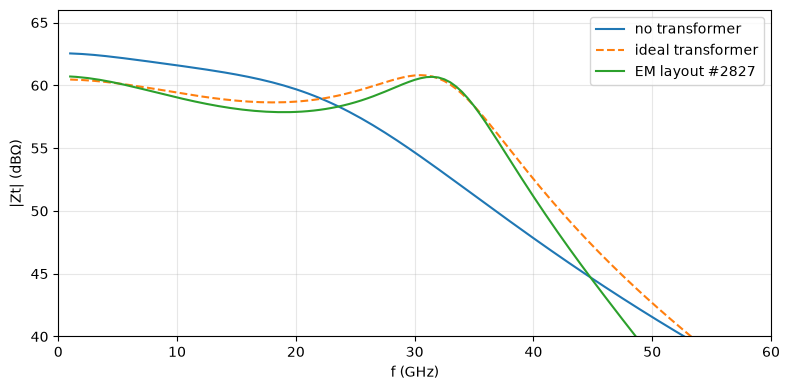

layout 2827 [3, 2, 1, 1, 143, 1, 1, 21, 3]


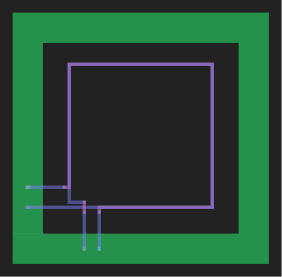

layout 2769 [3, 2, 1, 1, 155, 1, 1, 20, 3]


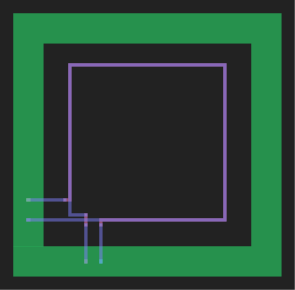

In [27]:
nx_p = json.load(open('results/noX_s123_cmp26_best.json'))['params']
ref_p = json.load(open('results/ideal_s123_ns1reg_best.json'))['params']
best = sorted([r for r in s1 if not r['swap'] and r['m']['meets']], key=lambda r: -r['m']['bw'])
resp = 'results/layout_resp.npz'
if not os.path.exists(resp):
    mx = T.run(nx_p, None, ('ideal', nx_p['L1']), ('ideal', nx_p['LB']), '123')
    d = np.load('results/xfmr_figures.npz')
    s_best = d[f"s{best[0]['idx']}"]
    ml = T.run(ref_p, ('sp', SU.FREQ, s_best), ('ideal', ref_p['L1']), ('ideal', ref_p['LB']), '123')
    mi = T.run(ref_p, ('ideal', ref_p['Lp'], ref_p['Ls'], ref_p['k']), ('ideal', ref_p['L1']), ('ideal', ref_p['LB']), '123')
    np.savez(resp, f=mx['f'], noX=np.abs(mx['zt']), lay=np.abs(ml['zt']), ideal=np.abs(mi['zt']), idx=best[0]['idx'])
r_ = np.load(resp)
plt.figure(figsize=(8, 4))
plt.plot(r_['f'] / 1e9, 20 * np.log10(r_['noX']), label='no transformer')
plt.plot(r_['f'] / 1e9, 20 * np.log10(r_['ideal']), '--', label='ideal transformer')
plt.plot(r_['f'] / 1e9, 20 * np.log10(r_['lay']), label=f"EM layout #{int(r_['idx'])}")
plt.xlim(0, 60); plt.ylim(40, 66); plt.xlabel('f (GHz)'); plt.ylabel('|Zt| (dB$\\Omega$)'); plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.show()
for i in [r['idx'] for r in best[:2]]:
    print('layout', i, info_geo(i)); display(Image(f'PNG/{i}.png', width=260))

## 9. EM Verification of the Optimised Design

The design returned by the surrogate co-design is simulated again: `verify.py` writes the GDS of the transformer and of the spiral inductors L1 and Lb, simulates them with openEMS,
and runs the TIA with the new S-parameter files. The difference between the surrogate prediction and the verified result tells how much the final bandwidth can be trusted.
`check_round.py` summarises the result and decides whether more EM samples around the optimum are needed.

In [28]:
%%writefile verify.py
# EM verification of co-designed transformer-RGC TIAs: generate GDS of the top surrogate-optimised designs (transformer,
# L1 and Lb spiral), run openEMS (Ray), re-simulate the TIA with the EM S-parameters and compare to the surrogate.
# Usage: python verify.py --stages 13 --tag run1 [--k 3] [--index0 90000]
# Indices: transformer 90000+, L1 index0+100+k, Lb index0+200+k (all kept out of the training range < 8000).
import argparse
import json
import os
import subprocess
import sys
import numpy as np
import skrf as rf
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import tia_sim as T
from surrogate import Surrogate, xfmr_figures, spiral_figures, F_IDX, FREQ
from codesign import xgeo, sgeo, RES, HERE, models_of

ap = argparse.ArgumentParser()
ap.add_argument('--stages', default='13')
ap.add_argument('--tag', default='run1')
ap.add_argument('--k', type=int, default=3)
ap.add_argument('--index0', type=int, default=90000)
ap.add_argument('--xmodel', default=f'{HERE}/models/xfmr.pt')
ap.add_argument('--smodel', default=f'{HERE}/models/spiral.pt')
a = ap.parse_args()
os.chdir(HERE)
sfx = f's{a.stages}_{a.tag}'

em = json.load(open(f'{RES}/em_{sfx}_best.json'))
cands = em['top5'][:a.k]
ix = [a.index0 + k for k in range(len(cands))]
i1 = [a.index0 + 100 + k for k in range(len(cands))]
ib = [a.index0 + 200 + k for k in range(len(cands))]

import xfmr_gen, spiral_gen
for k, c in enumerate(cands):
	for i, gen, g in ((ix[k], xfmr_gen, xgeo(c['params'])), (i1[k], spiral_gen, sgeo(c['params'], 'l1')),
					  (ib[k], spiral_gen, sgeo(c['params'], 'lb'))):
		if not os.path.exists(f'GDS/{i}.gds'):
			gen.one_sample(i, g)


def ext(i):
	return 's4p' if i in ix else 's2p'


allidx = ix + i1 + ib
if not all(os.path.exists(f'SPData/{i}.{ext(i)}') for i in allidx):
	subprocess.run([sys.executable, 'emx_sim.py', '--list', ','.join(map(str, allidx))], check=True)


def load(i):
	n = rf.Network(f'SPData/{i}.{ext(i)}')
	s = n.s[F_IDX]
	return 0.5 * (s + np.swapaxes(s, -1, -2))


sx, ss = Surrogate(a.xmodel), Surrogate(a.smodel)
rows, curves, stats = [], {}, []
for name in ('noX', 'ideal'):
	fn = f'{RES}/{name}_s{a.stages}_{a.tag}_best.json'
	if os.path.exists(fn):
		b = json.load(open(fn))
		m = T.run(b['params'], *models_of(b['params'], name), stages=a.stages)
		curves[name] = m
		rows.append((name, T.summary(m), ''))
for k, c in enumerate(cands):
	p = c['params']
	if not all(os.path.exists(f'SPData/{i}.{ext(i)}') for i in (ix[k], i1[k], ib[k])):
		rows.append((f'em#{k} {xgeo(p)}', 'EM FAILED', ''))
		continue
	e_x, e_1, e_b = load(ix[k]), load(i1[k]), load(ib[k])
	su_x, su_1, su_b = (sx.predict([xgeo(p)])[0], ss.predict([sgeo(p, 'l1')])[0], ss.predict([sgeo(p, 'lb')])[0])
	run = lambda x, l1, lb: T.run(p, ('sp', FREQ, x), ('sp', FREQ, l1), ('sp', FREQ, lb), a.stages)
	m_su, m_em = run(su_x, su_1, su_b), run(e_x, e_1, e_b)
	# which passive matters: EM transformer with surrogate spirals and vice versa
	m_mix = run(e_x, su_1, su_b)
	fs, fe = xfmr_figures(FREQ, su_x), xfmr_figures(FREQ, e_x)
	ind = (f"Lp {fs['Lp10']*1e9:.3f}/{fe['Lp10']*1e9:.3f} nH  Ls {fs['Ls10']*1e9:.3f}/{fe['Ls10']*1e9:.3f} nH  "
		   f"k {fs['k10']:.3f}/{fe['k10']:.3f}  SRF {fs['SRF']/1e9:.0f}/{fe['SRF']/1e9:.0f} GHz  "
		   f"max|dS| xfmr {np.abs(su_x - e_x).max():.3f} L1 {np.abs(su_1 - e_1).max():.3f} Lb {np.abs(su_b - e_b).max():.3f}")
	geo = xgeo(p)
	rows.append((f'em#{k} {geo} surrogate', T.summary(m_su), ind))
	rows.append((f'em#{k} {geo} EM-verified', T.summary(m_em), ''))
	rows.append((f'em#{k} {geo} EM xfmr only', T.summary(m_mix), ''))
	curves[f'em#{k} surrogate'], curves[f'em#{k} EM'] = m_su, m_em
	if m_su is not None and m_em is not None:
		stats.append(dict(index=ix[k], geo=geo, params=p, cost_su=T.cost(m_su), cost_em=T.cost(m_em),
						  **{f'{q}_su': m_su[q] for q in T.SPEC}, **{f'{q}_em': m_em[q] for q in T.SPEC},
						  Lp10_su=fs['Lp10'], Lp10_em=fe['Lp10'], k_su=fs['k10'], k_em=fe['k10'],
						  max_dS=float(max(np.abs(su_x - e_x).max(), np.abs(su_1 - e_1).max(), np.abs(su_b - e_b).max()))))

with open(f'{RES}/verify_{sfx}.json', 'w') as fo:
	json.dump(stats, fo, indent=1, default=float)
report = '\n'.join(f'{n:50s} {s}\n{"":50s} {x}' if x else f'{n:50s} {s}' for n, s, x in rows)
print(report)
with open(f'{RES}/verify_{sfx}.txt', 'w') as fo:
	fo.write(report + '\n')

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name, m in curves.items():
	if m is None:
		continue
	f = m['f'] / 1e9
	ls = '--' if 'surrogate' in name else '-'
	ax[0].plot(f, 20 * np.log10(np.abs(m['zt'])), ls, label=name)
	ax[1].plot(f, -np.gradient(np.unwrap(np.angle(m['zt'])), 2 * np.pi * m['f']) * 1e12, ls, label=name)
ax[0].axhline(T.SPEC['zt_dbohm'] - 3, color='k', lw=0.5)
ax[0].axvline(T.SPEC['bw_ghz'], color='k', lw=0.5)
ax[0].set(xlabel='GHz', ylabel='differential Zt (dBOhm)', xlim=(1, 80))
ax[1].set(xlabel='GHz', ylabel='group delay (ps)', xlim=(1, 60))
ax[0].legend(fontsize=8)
for x in ax:
	x.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(f'{RES}/verify_{sfx}.png', dpi=120)

Overwriting verify.py


In [29]:
fs = sorted(glob.glob('results/verify_*.txt')) + sorted(glob.glob('results/check_*.txt'))
for f in fs:
    print('====', f); print(open(f).read())
if not fs: print('verification not run yet')

verification not run yet


## Conclusion

In [30]:
nxm = json.load(open('results/noX_s123_cmp26_best.json'))['metrics']
idm = json.load(open('results/ideal_s123_cmp26_best.json'))['metrics']
nrm = json.load(open('results/ideal_s123_ns1reg_best.json'))['metrics']
bl = sorted([r for r in s1 if not r['swap'] and r['m']['meets']], key=lambda r: -r['m']['bw'])
txt = f'''
* **Without a transformer**, the three-stage TIA reaches **{nxm['bw_ghz']:.1f} GHz** with Zt = {nxm['zt_dbohm']:.1f} dB$\\Omega$, {nxm['noise_pa']:.1f} pA/$\\sqrt{{Hz}}$ and {nxm['power_mw']:.1f} mW. It does not reach the 26 GHz target.
* **With ideal coupled inductors**, the bandwidth is {idm['bw_ghz']:.1f} GHz for $k \\le 0.72$, and {nrm['bw_ghz']:.1f} GHz inside the (Lp, Ls, k) range that single-turn EM layouts realise.
* **With real EM transformers** ({len(idx)} simulated layouts) the coupling stays near $k \\approx 0.5$ for the layouts with a useful inductance. In the TIA with the fixed bias of the ideal design,
  {len(bl)} layouts meet all specifications; the best are '''
txt += ', '.join(f"#{r['idx']} ({r['m']['bw']:.1f} GHz, Lp {r['fig'][0]:.2f} nH, Ls {r['fig'][1]:.2f} nH, k {r['fig'][2]:.2f})" for r in bl[:3])
txt += f'''. The transformer therefore raises the bandwidth from {nxm['bw_ghz']:.1f} GHz to {bl[0]['m']['bw']:.1f} GHz ({(bl[0]['m']['bw']/nxm['bw_ghz']-1)*100:.0f} % more) at the same
  noise and power limits, and the 26 GHz target is exceeded with margin.
'''
display(Markdown(txt))


* **Without a transformer**, the three-stage TIA reaches **20.5 GHz** with Zt = 62.5 dB$\Omega$, 20.9 pA/$\sqrt{Hz}$ and 27.8 mW. It does not reach the 26 GHz target.
* **With ideal coupled inductors**, the bandwidth is 38.0 GHz for $k \le 0.72$, and 35.8 GHz inside the (Lp, Ls, k) range that single-turn EM layouts realise.
* **With real EM transformers** (911 simulated layouts) the coupling stays near $k \approx 0.5$ for the layouts with a useful inductance. In the TIA with the fixed bias of the ideal design,
  2 layouts meet all specifications; the best are #2827 (35.5 GHz, Lp 0.44 nH, Ls 0.51 nH, k 0.43), #2769 (35.0 GHz, Lp 0.48 nH, Ls 0.56 nH, k 0.45). The transformer therefore raises the bandwidth from 20.5 GHz to 35.5 GHz (73 % more) at the same
  noise and power limits, and the 26 GHz target is exceeded with margin.


**What the data say about the transformer.** A coupling of about 0.5 is enough: the bandwidth gain does not come from a record coupling factor but from the correct inductance level
($L_p \approx 0.45$ to 0.5 nH, $L_s \approx 0.5$ to 0.65 nH) together with a self-resonance above 50 GHz, which only single-turn stacked layouts offer. Layouts with more turns couple more strongly but have too much
secondary inductance and too low a self-resonance.

**Limits of the present result.**

* L1 and Lb are ideal in the optimisation rows and in the layout screening; their EM models are available (Section 5) and are used in the surrogate-in-the-loop runs.
* In the layout screening the active circuit is not re-optimised for each layout; the numbers are a lower bound of what a joint optimisation can reach.
* The EM verification of the optimised design (Section 9) is the final check and must be read together with the surrogate error.

## To Do

* Run the surrogate-in-the-loop co-design (`--mode em`) with the retrained transformer surrogate and verify the best three designs with `verify.py`.
* Add the pad and the interconnect between the photodiode and L1 to the EM model.
* Explore a third metal layer for the primary (TopMetal1 and Metal5 stacks) to raise $k$ above 0.5 without extra turns.

## References

1. S. Li and S. Palermo, "Low-Power 26-GHz Transformer-Based Regulated Cascode SiGe BiCMOS Transimpedance Amplifier," IEEE Journal of Solid-State Circuits, vol. 48, no. 5, 2013.
2. N. Hansen, "The CMA Evolution Strategy: A Tutorial," arXiv:1604.00772, 2016.
3. T. Akiba et al., "Optuna: A Next-generation Hyperparameter Optimization Framework," KDD 2019.
4. T. Liebig et al., "openEMS - a free and open source equivalent-circuit (EC) FDTD simulation platform," 2013.
5. P. Moritz et al., "Ray: A Distributed Framework for Emerging AI Applications," OSDI 2018.
6. IHP GmbH, "IHP-Open-PDK SG13G2," https://github.com/IHP-GmbH/IHP-Open-PDK